# Jupyter Notebooks in Data Availability Statements (2011–2025)
### A Comprehensive Longitudinal Analysis

This notebook investigates **when**, **where**, and **why** Jupyter notebooks appear
in PubMed Central Data Availability Statements across 15 years of biomedical publishing,
centred on the 2016 FAIR principles paper by Wilkinson et al.

## Historical timeline

| Year | Event |
|------|-------|
| 2011 | IPython Notebook 0.12 released |
| **2014** | **Project Jupyter founded — `.ipynb` format standardised** |
| 2015 | JupyterHub, nbviewer public; R Markdown matures |
| **2016** | **FAIR principles (Wilkinson et al., March); mybinder.org** |
| 2017 | Google Colab; Jupyter wins ACM Software System Award |
| 2018 | JupyterLab 1.0; Binder production-stable |
| **2019** | **Widespread funder/journal open-code mandates** |
| 2021 | Jupyter Book; EOSC mandate wave in Europe |
| 2022 | Code Ocean enterprise; Colab Pro widely adopted |

## Four analytical eras

| Era | Years | Defining context |
|-----|-------|-----------------|
| **Pre-Jupyter** | 2012–13 | No `.ipynb`; only R/MATLAB scripts or SPSS syntax |
| **Jupyter adoption** | 2014–15 | Format exists, not yet mainstream in biomedical DAS |
| **FAIR era** | 2016–18 | FAIR principles + Binder + Colab emerge together |
| **Mandate era** | 2019–24 | Funder open-code mandates enter DAS language |

## Section map

| § | Title | Key questions |
|---|-------|--------------|
| 0 | Setup — detection engine, master frame | 5-layer detection; era labels |
| 1 | Prevalence over time | How fast is adoption growing? |
| 2 | Pre/Post FAIR — interrupted time series | Did 2016 accelerate notebook sharing? |
| 3 | Pre/Post Jupyter — what came before? | Did scripts already lift data-sharing scores? |
| 4 | data-sharing score uplift — violin + Mann-Whitney | How much does a notebook improve the data-sharing score? |
| 5 | Platform evolution | GitHub → Binder → Colab: how did hosting change? |
| 6 | Repository tier — persistent DOI vs ephemeral | Do authors pick high-tier hosts? |
| 7 | DAS quality signals | Do notebooks co-occur with richer DAS language? |
| 8 | DAS vocabulary — 15 keyword patterns | What language predicts notebook sharing? |
| 9 | JATS4R compliance × notebooks | Does XML quality correlate with sharing culture? |
| 10 | Author count × notebooks | Do collaborative papers share more code? |
| 11 | data-sharing score quartile analysis | Are notebooks concentrated in high-scoring papers? |
| 12 | Temporal co-evolution | How do notebooks, DAS, and ethics grow together? |
| 13 | Keyword co-occurrence heatmap | Which DAS terms cluster with notebooks? |
| 14 | Ethics × DAS × Notebook gold-standard | Three-way analysis |
| 15 | Journal-level scatter + adoption s-curve | Which journals lead and how fast do others follow? |
| 16 | Publisher league table | |
| 17 | OA tier × notebooks *(Stage 6)* | |
| 18 | Discipline breakdown *(Stage 6)* | |
| 19 | Funder breakdown *(Stage 6)* | |
| 20 | Statistical summary + exports | |


In [1]:
import importlib.util, subprocess, sys

# A bare `pip install ...` here resolves to whatever `pip` is first on
# $PATH, not this kernel's own interpreter -- in this environment that is
# a separate, PEP-668 "externally managed" pip that refuses to run at all,
# even when every package below is already installed in this kernel's own
# venv. Check first, and if actually needed, install via
# `sys.executable -m pip` so it always targets this kernel's environment
# instead of whatever's on PATH.
_required = ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scipy']
_import_name = {}
_missing = [pkg for pkg in _required
            if importlib.util.find_spec(_import_name.get(pkg, pkg.replace("-", "_"))) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *_missing])
else:
    print("Required packages already installed.")

Required packages already installed.


---
## §0 — Setup, Detection Engine, Master Frame

In [2]:
import sqlite3, warnings, re
import matplotlib; import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.patches as mpatches
import pandas as pd
import numpy as np
import seaborn as sns
from scipy import stats
from pathlib import Path

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', font_scale=1.15)
FIG_W, FIG_H = 14, 5

# ── Milestone years ────────────────────────────────────────────────────────
JUPYTER_YEAR = 2014
FAIR_YEAR    = 2016
COLAB_YEAR   = 2017
MANDATE_YEAR = 2019

# ── Colour palette ────────────────────────────────────────────────────────
C_NB    = '#f28e2b'   # notebook  — orange
C_CODE  = '#59a14f'   # code repo — green
C_SCRP  = '#76b7b2'   # script    — teal
C_NONE  = '#bab0ac'   # no code   — grey
C_PRE   = '#4e79a7'   # pre-FAIR  — blue
C_POST  = '#e15759'   # post-FAIR — red
C_COMP  = '#2ca02c'   # JATS4R compliant
C_ETH   = '#9467bd'   # ethics    — purple

MILESTONES = [
    (JUPYTER_YEAR - 0.33, C_CODE, '--', 'Jupyter (2014)'),
    (FAIR_YEAR    - 0.33, C_POST, '-',  'FAIR (2016)'),
    (COLAB_YEAR   - 0.33, C_NB,   ':',  'Colab (2017)'),
    (MANDATE_YEAR - 0.33, C_ETH,  '-.', 'Mandates (2019)'),
]

DB_PATH = Path('../data/processed/pmc_fair.db')
assert DB_PATH.exists(), f'Database not found: {DB_PATH}'

FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
SAVEFIG_KWARGS = dict(dpi=150, bbox_inches="tight")
con = sqlite3.connect(DB_PATH)

def qdb(sql, params=()):
    return pd.read_sql_query(sql, con, params=params)

tables = {r[0] for r in con.execute(
    'SELECT name FROM sqlite_master WHERE type="table"').fetchall()}

HAS_DISC   = 'article_discipline'    in tables
HAS_FUNDER = 'article_funder'        in tables
HAS_OA     = 'journal_oa'            in tables
HAS_SUPP   = 'supplementary_material' in tables
HAS_RC     = 'repo_classification'   in tables
HAS_ETHICS = 'ethics_statement'      in tables

for lbl, flag in [('Discipline (Stage 6)', HAS_DISC),
                  ('Funder     (Stage 6)', HAS_FUNDER),
                  ('OA status            ', HAS_OA),
                  ('Repo classification  ', HAS_RC),
                  ('Suppl. material      ', HAS_SUPP),
                  ('Ethics statement     ', HAS_ETHICS)]:
    print(f'  {"OK" if flag else "--"}  {lbl}')

# `article.year` is precomputed by pipeline/derive_year.py (pub_year anchor,
# epub_date only within +/-1 year, accepted_date/received_date as a last-resort
# fallback) -- see that script for the full derivation logic and rationale.
# This notebook just reads it directly; it doesn't recompute anything.
assert 'year' in {r[1] for r in con.execute("PRAGMA table_info(article)").fetchall()}, \
    "article.year not found -- run `python pipeline/derive_year.py --db <path>` first"


  OK  Discipline (Stage 6)
  OK  Funder     (Stage 6)
  OK  OA status            
  OK  Repo classification  
  OK  Suppl. material      
  OK  Ethics statement     


### Detection engine — 5 layers

| Layer | Source | Signal |
|---|---|---|
| 1 | `data_availability.statement` text | `jupyter`, `.ipynb`, `nbviewer`, `binder`, `colab`, `deepnote`, `code ocean` |
| 2 | `da_link.url` | Domain/path patterns for all notebook platforms |
| 3 | `supplementary_material` | `.ipynb` in URL or caption; `notebook` in media_type |
| 4 | `repo_classification` | `repo_type = code_repository` |
| 5 | Vocabulary proxy | `reproducib*`, `workflow`, `snakemake`, `nextflow`, `cwl` |

In [3]:
NB_TEXT_RE = re.compile(
    r'jupyter|\.ipynb\b|\bnbviewer\b'
    r'|mybinder\.org|binder\.'
    r'|colab\.research\.google|colab\.google|\bcolab\b'
    r'|\bdeepnote\b|kaggle\.com/code'
    r'|code\s+ocean|codeocean\.com'
    r'|(?:python|ipython|computational|analysis)\s+notebook',
    re.I)

NB_URL_RE = re.compile(
    r'nbviewer\.jupyter\.org|mybinder\.org'
    r'|colab\.research\.google\.com|codeocean\.com'
    r'|deepnote\.com|kaggle\.com/code|\.ipynb(?:\b|$)',
    re.I)

SCRIPT_RE = re.compile(
    r'\.r\b|\.rmd\b|\.rdata\b|\br\s+script|\.m\b|\bmatlab\b'
    r'|\.py\b|python\s+script|\.sas\b|\.spss\b|syntax\s+file'
    r'|supplementary\s+(?:code|script|software)',
    re.I)

REPRO_RE = re.compile(
    r'reproducib|\bworkflow\b|computational\s+(?:analysis|methods|pipeline)'
    r'|snakemake|nextflow|\bcwl\b|nf-core|\bwdl\b',
    re.I)

PLATFORM_PATTERNS = [
    ('GitHub / GitLab',   re.compile(r'github\.com|gitlab\.com', re.I)),
    ('Binder',            re.compile(r'mybinder\.org|binder\.', re.I)),
    ('Google Colab',      re.compile(r'colab\.research\.google|colab\.google|\bcolab\b', re.I)),
    ('Code Ocean',        re.compile(r'codeocean\.com|code\s+ocean', re.I)),
    ('nbviewer',          re.compile(r'nbviewer\.jupyter\.org', re.I)),
    ('Kaggle',            re.compile(r'kaggle\.com/code', re.I)),
    ('Deepnote',          re.compile(r'deepnote\.com', re.I)),
    ('Zenodo (notebook)', re.compile(r'zenodo\.org.*\.ipynb|\.ipynb.*zenodo', re.I)),
]
print('Patterns ready.')


Patterns ready.


In [4]:
# ── Layer 1-4 flags ───────────────────────────────────────────────────────
df_das = qdb("""SELECT da.article_id, da.statement AS das_text
               FROM data_availability da""")
df_das['nb_text']     = df_das['das_text'].apply(lambda t: bool(NB_TEXT_RE.search(str(t))) if t else False)
df_das['script_text'] = df_das['das_text'].apply(lambda t: bool(SCRIPT_RE.search(str(t)))  if t else False)
df_das['repro_text']  = df_das['das_text'].apply(lambda t: bool(REPRO_RE.search(str(t)))   if t else False)

df_urls = qdb("""SELECT da.article_id, dl.url
               FROM data_availability da JOIN da_link dl ON dl.da_id = da.da_id""")
nb_url_arts = set(df_urls[df_urls['url'].apply(
    lambda u: bool(NB_URL_RE.search(str(u))) if u else False)]['article_id'])

if HAS_SUPP:
    df_supp = qdb("""SELECT article_id, COALESCE(url,'') AS url,
                          COALESCE(caption,'') AS cap, COALESCE(media_type,'') AS mt
                   FROM supplementary_material""")
    nb_supp_arts = set(df_supp[
        df_supp['url'].str.contains(r'\.ipynb', case=False, na=False, regex=True) |
        df_supp['cap'].apply(lambda c: bool(NB_TEXT_RE.search(str(c)))) |
        df_supp['mt'].str.contains('notebook', case=False, na=False)
    ]['article_id'])
else:
    nb_supp_arts = set()

if HAS_RC:
    df_rc = qdb("""SELECT da.article_id FROM data_availability da
                  JOIN da_link dl ON dl.da_id = da.da_id
                  JOIN repo_classification rc ON rc.link_id = dl.link_id
                  WHERE rc.repo_type = 'code_repository'""")
    code_repo_arts = set(df_rc['article_id'])
else:
    code_repo_arts = set()

df_das['nb_url']        = df_das['article_id'].isin(nb_url_arts)
df_das['nb_supp']       = df_das['article_id'].isin(nb_supp_arts)
df_das['has_notebook']  = df_das['nb_text'] | df_das['nb_url'] | df_das['nb_supp']
df_das['has_code_repo'] = df_das['article_id'].isin(code_repo_arts)
df_das['has_any_code']  = df_das['has_notebook'] | df_das['has_code_repo']

for lbl, s in [('DAS articles', len(df_das)),
               ('L1 NB text', df_das['nb_text'].sum()),
               ('L2 NB URL',  len(nb_url_arts)),
               ('L3 NB supp', len(nb_supp_arts)),
               ('L4 code repo', len(code_repo_arts)),
               ('has_notebook', df_das['has_notebook'].sum()),
               ('has_any_code', df_das['has_any_code'].sum())]:
    print(f'  {lbl:22} {int(s):>10,}')


  DAS articles            3,013,543
  L1 NB text                  2,275
  L2 NB URL                     561
  L3 NB supp                    254
  L4 code repo               92,731
  has_notebook                2,470
  has_any_code               93,657


In [5]:
# ── Master frame ─────────────────────────────────────────────────────────
df = qdb("""
    SELECT a.article_id, a.year AS year,
           a.journal_id, 
           COALESCE(da.source,'') AS das_source,
           dc.data_sharing_score, dc.primary_category AS das_cat,
           dc.mentions_license, dc.mentions_doi, dc.mentions_github,
           dc.has_url, dc.has_accession,
           dc.word_count AS das_words, dc.sentence_count AS das_sents
    FROM article a
    JOIN das_category dc ON dc.article_id = a.article_id
    LEFT JOIN data_availability da ON da.article_id = a.article_id
    WHERE a.year BETWEEN 2011 AND 2025
""")

FLAG_COLS = ['has_notebook','has_code_repo','has_any_code',
             'nb_text','nb_url','nb_supp','script_text','repro_text']
df = df.merge(df_das[['article_id'] + FLAG_COLS], on='article_id', how='left')
for c in FLAG_COLS:
    df[c] = df[c].fillna(False).astype(bool)

jrnl = qdb('SELECT journal_id, title AS jrnl_title, publisher FROM journal')
df   = df.merge(jrnl, on='journal_id', how='left')

df['has_das'] = df['das_source'].str.strip().ne('')

_DT = re.compile(r"^sec\[@sec-type='(.+)'\]$")
def classify_das(s):
    s = str(s or '').strip()
    if not s: return 'no_das'
    if s == "sec[@sec-type='data-availability']": return 'compliant'
    if _DT.match(s): return 'near_miss'
    if s.startswith('sec/title='): return 'title_only'
    return 'non_standard'
df['das_tier']      = df['das_source'].apply(classify_das)
df['das_compliant'] = (df['das_tier'] == 'compliant')

if HAS_ETHICS:
    eth_ids = set(qdb('SELECT article_id FROM ethics_statement')['article_id'])
    df['has_ethics'] = df['article_id'].isin(eth_ids)
else:
    df['has_ethics'] = False

if HAS_OA:
    oa = qdb("SELECT journal_id, COALESCE(oa_status,'unknown') AS oa_status FROM journal_oa")
    df = df.merge(oa, on='journal_id', how='left')
    df['oa_status'] = df['oa_status'].fillna('unknown')

def code_type(row):
    if row['has_notebook']:  return 'Jupyter notebook'
    if row['script_text']:   return 'Script (R/MATLAB/Python)'
    if row['has_code_repo']: return 'Code repository'
    return 'No code signal'
df['code_type'] = df.apply(code_type, axis=1)
CT_ORDER = ['Jupyter notebook','Code repository','Script (R/MATLAB/Python)','No code signal']
CT_CLRS  = [C_NB, C_CODE, C_SCRP, C_NONE]

def nb_group(row):
    if row['has_notebook']:  return 'Notebook'
    if row['has_code_repo']: return 'Code repo only'
    return 'No code signal'
df['nb_grp'] = df.apply(nb_group, axis=1)
G_ORDER = ['Notebook','Code repo only','No code signal']
G_CLRS  = [C_NB, C_CODE, C_NONE]

ERA_ORDER = ['Pre-Jupyter (2012-13)','Jupyter (2014-15)','FAIR era (2016-18)','Mandate era (2019-25)']
def era_label(y):
    if y <= 2013: return ERA_ORDER[0]
    if y <= 2015: return ERA_ORDER[1]
    if y <= 2018: return ERA_ORDER[2]
    return ERA_ORDER[3]
df['era'] = df['year'].apply(era_label)

yr = (df.groupby('year').agg(
    n_total    = ('article_id','count'),
    n_notebook = ('has_notebook','sum'),
    n_code     = ('has_code_repo','sum'),
    n_any      = ('has_any_code','sum'),
    n_das      = ('has_das','sum'),
).reset_index())
yr['pct_nb']    = yr['n_notebook'] / yr['n_total'] * 100
yr['pct_code']  = yr['n_code']     / yr['n_total'] * 100
yr['pct_any']   = yr['n_any']      / yr['n_total'] * 100
yr['nb_of_das'] = yr['n_notebook'] / yr['n_das'].clip(1) * 100

print(f'Master frame: {len(df):,} articles  ×  {len(df.columns)} columns')
print(f'  has_notebook  {df["has_notebook"].sum():>8,}  ({df["has_notebook"].mean()*100:.2f}%)')
print(f'  has_any_code  {df["has_any_code"].sum():>8,}  ({df["has_any_code"].mean()*100:.2f}%)')
print(f'  has_das       {df["has_das"].sum():>8,}  ({df["has_das"].mean()*100:.2f}%)')


Master frame: 6,874,176 articles  ×  31 columns
  has_notebook     2,464  (0.04%)
  has_any_code    93,491  (1.36%)
  has_das       3,011,043  (43.80%)


---
## §1 — Prevalence Over Time

Three views: share of the whole corpus, share of DAS-bearing articles only
(controlling for rising DAS adoption), and absolute stacked counts.
All four milestone lines annotated.

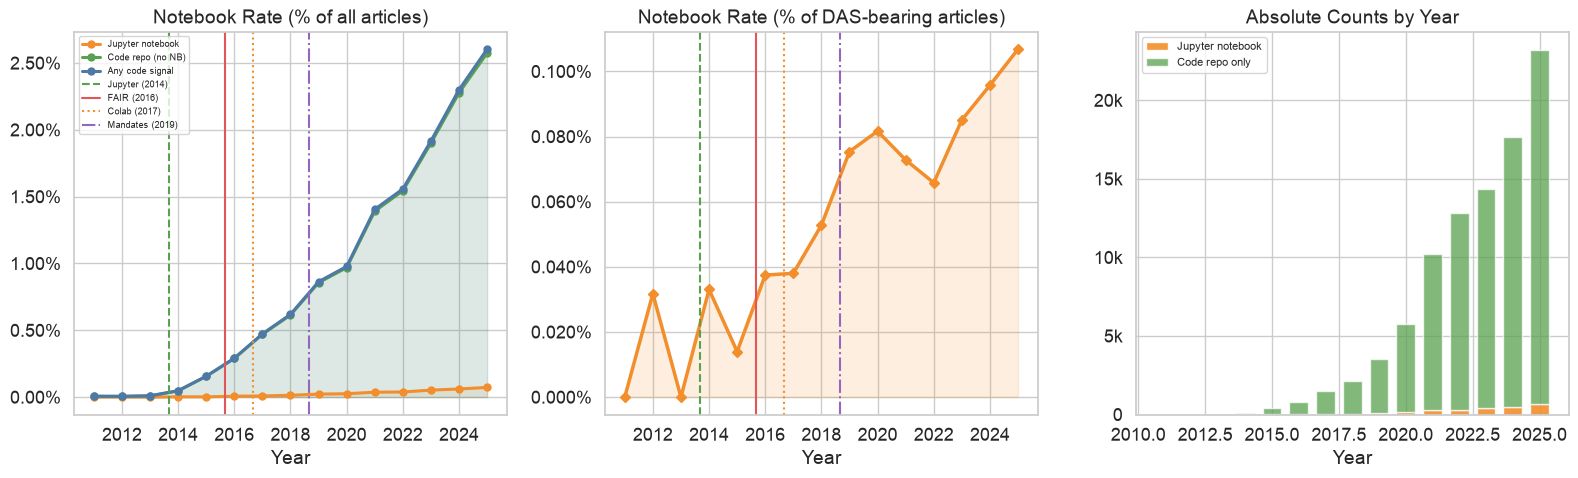

 year  n_total  n_notebook  pct_nb  nb_of_das
 2011   110347           0    0.00       0.00
 2012   148267           1    0.00       0.03
 2013   187212           0    0.00       0.00
 2014   223496           5    0.00       0.03
 2015   252745           5    0.00       0.01
 2016   277445          19    0.01       0.04
 2017   318654          28    0.01       0.04
 2018   349018          48    0.01       0.05
 2019   414163          94    0.02       0.08
 2020   595499         150    0.03       0.08
 2021   734002         271    0.04       0.07
 2022   830189         319    0.04       0.07
 2023   754942         396    0.05       0.09
 2024   776984         474    0.06       0.10
 2025   901213         654    0.07       0.11


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H))

ax = axes[0]
for col, clr, lbl in [('pct_nb',C_NB,'Jupyter notebook'),
                       ('pct_code',C_CODE,'Code repo (no NB)'),
                       ('pct_any',C_PRE,'Any code signal')]:
    ax.fill_between(yr['year'], yr[col], alpha=0.10, color=clr)
    ax.plot(yr['year'], yr[col], lw=2.2, marker='o', ms=5, color=clr, label=lbl)
for x, c, ls, lbl in MILESTONES:
    ax.axvline(x, color=c, lw=1.5, ls=ls, label=lbl)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Notebook Rate (% of all articles)'); ax.set_xlabel('Year')
ax.legend(fontsize=6.5)

ax = axes[1]
ax.fill_between(yr['year'], yr['nb_of_das'], alpha=0.15, color=C_NB)
ax.plot(yr['year'], yr['nb_of_das'], lw=2.5, marker='D', ms=5, color=C_NB)
for x, c, ls, _ in MILESTONES:
    ax.axvline(x, color=c, lw=1.5, ls=ls)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Notebook Rate (% of DAS-bearing articles)'); ax.set_xlabel('Year')

ax = axes[2]
nb_only    = yr['n_notebook']
code_extra = (yr['n_code'] - yr['n_notebook']).clip(lower=0)
ax.bar(yr['year'], nb_only,    color=C_NB,   alpha=0.90, label='Jupyter notebook', width=0.7)
ax.bar(yr['year'], code_extra, color=C_CODE, alpha=0.75, label='Code repo only',
       bottom=nb_only, width=0.7)
ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda v, _: f'{v/1000:.0f}k' if v >= 1000 else str(int(v))))
ax.set_title('Absolute Counts by Year'); ax.set_xlabel('Year'); ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_nb_01_prevalence.png", **SAVEFIG_KWARGS)
plt.show()
print(yr[['year','n_total','n_notebook','pct_nb','nb_of_das']].round(2).to_string(index=False))


---
## §2 — Pre/Post FAIR: Interrupted Time Series

Tests whether the 2016 FAIR paper created a structural break in notebook adoption.
Three panels: OLS slopes pre/post, four-era bar with CAGR, and the FAIR-score
gap (notebook − no-code) measured in each period — testing if the gap is widening.

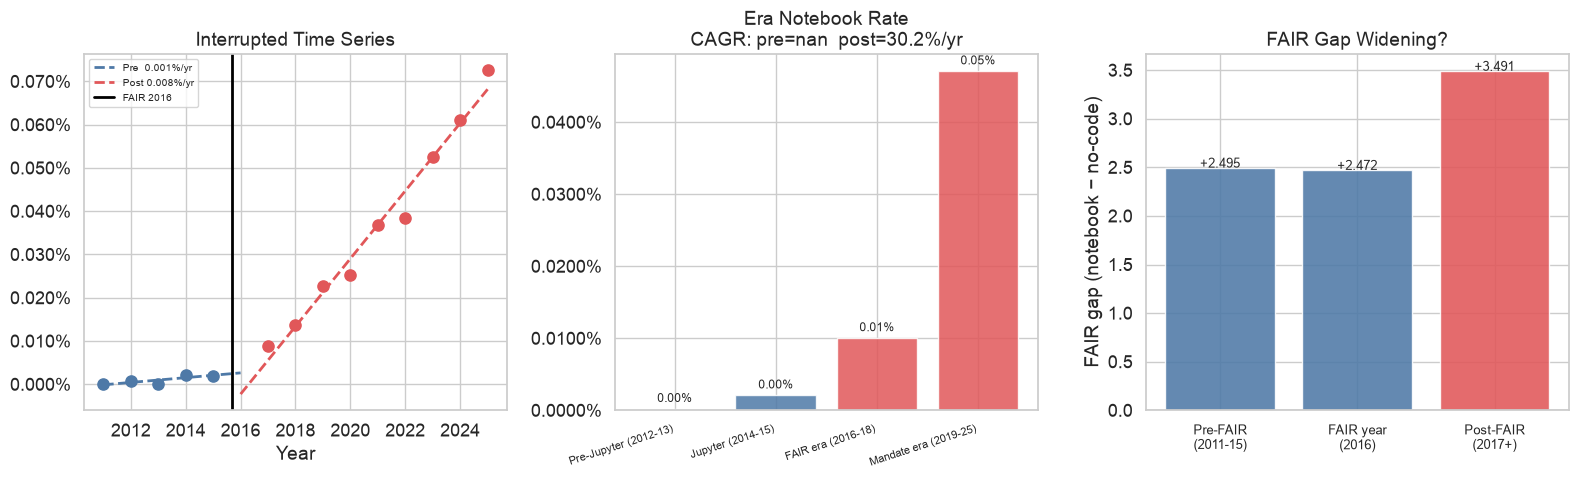

CAGR pre-FAIR : +nan%/yr
CAGR post-FAIR: +30.2%/yr


In [7]:
yr_pre  = yr[yr['year'] <  FAIR_YEAR]
yr_post = yr[yr['year'] >  FAIR_YEAR]

def cagr(s):
    v = s.dropna().values
    if len(v) < 2 or v[0] == 0: return float('nan')
    return ((v[-1] / v[0]) ** (1 / (len(v) - 1)) - 1) * 100

cagr_pre  = cagr(yr_pre['pct_nb'])
cagr_post = cagr(yr_post['pct_nb'])

fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H))

ax = axes[0]
ax.scatter(yr_pre['year'],  yr_pre['pct_nb'],  color=C_PRE,  s=65, zorder=5)
ax.scatter(yr_post['year'], yr_post['pct_nb'], color=C_POST, s=65, zorder=5)
if len(yr_pre) >= 2:
    sl, ic, _, _, _ = stats.linregress(yr_pre['year'], yr_pre['pct_nb'])
    ax.plot(np.linspace(2011, FAIR_YEAR, 40), ic + sl*np.linspace(2011, FAIR_YEAR, 40),
            color=C_PRE, lw=2, ls='--', label=f'Pre  {sl:.3f}%/yr')
if len(yr_post) >= 2:
    sl2, ic2, _, _, _ = stats.linregress(yr_post['year'], yr_post['pct_nb'])
    ax.plot(np.linspace(FAIR_YEAR, 2025, 40), ic2 + sl2*np.linspace(FAIR_YEAR, 2025, 40),
            color=C_POST, lw=2, ls='--', label=f'Post {sl2:.3f}%/yr')
ax.axvline(FAIR_YEAR - 0.33, color='black', lw=2, ls='-', label='FAIR 2016')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Interrupted Time Series'); ax.set_xlabel('Year'); ax.legend(fontsize=7.5)

ax = axes[1]
era_agg = df.groupby('era')['has_notebook'].mean().reindex(ERA_ORDER) * 100
bars = ax.bar(range(len(ERA_ORDER)), era_agg.values,
              color=[C_PRE,C_PRE,C_POST,C_POST], alpha=0.85, edgecolor='white')
ax.bar_label(bars, fmt='{:.2f}%', padding=3, fontsize=8.5)
ax.set_xticks(range(len(ERA_ORDER)))
ax.set_xticklabels(ERA_ORDER, rotation=18, ha='right', fontsize=8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title(f'Era Notebook Rate\nCAGR: pre={cagr_pre:.1f}  post={cagr_post:.1f}%/yr')

ax = axes[2]
periods = {'Pre-FAIR\n(2011-15)': df[df['year'] < FAIR_YEAR],
           'FAIR year\n(2016)':   df[df['year'] == FAIR_YEAR],
           'Post-FAIR\n(2017+)':  df[df['year'] > FAIR_YEAR]}
gaps, lbls, gclrs = [], [], []
for lbl, sub in periods.items():
    nb_s = sub[sub['has_notebook']  ]['data_sharing_score'].dropna()
    no_s = sub[~sub['has_any_code'] ]['data_sharing_score'].dropna()
    if len(nb_s) >= 2 and len(no_s) >= 2:
        gaps.append(nb_s.mean() - no_s.mean()); lbls.append(lbl)
        gclrs.append(C_POST if 'Post' in lbl else C_PRE)
ax.bar(range(len(lbls)), gaps, color=gclrs, alpha=0.88, edgecolor='white')
for i, g in enumerate(gaps): ax.text(i, g + 0.002, f'{g:+.3f}', ha='center', fontsize=9)
ax.set_xticks(range(len(lbls))); ax.set_xticklabels(lbls, fontsize=9)
ax.axhline(0, color='black', lw=0.8)
ax.set_ylabel('FAIR gap (notebook − no-code)'); ax.set_title('FAIR Gap Widening?')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_nb_02_pre_post_fair.png", **SAVEFIG_KWARGS)
plt.show()
print(f'CAGR pre-FAIR : {cagr_pre:+.1f}%/yr')
print(f'CAGR post-FAIR: {cagr_post:+.1f}%/yr')


---
## §3 — Pre/Post Jupyter: What Did Code-Sharing Look Like Before 2014?

Before Project Jupyter, code-sharing meant R/MATLAB/Python scripts or SPSS syntax
uploaded as supplementary files. We test whether those older practices already
lifted data-sharing scores — or whether the notebook format's narrated, reproducible
structure is what drives the uplift.

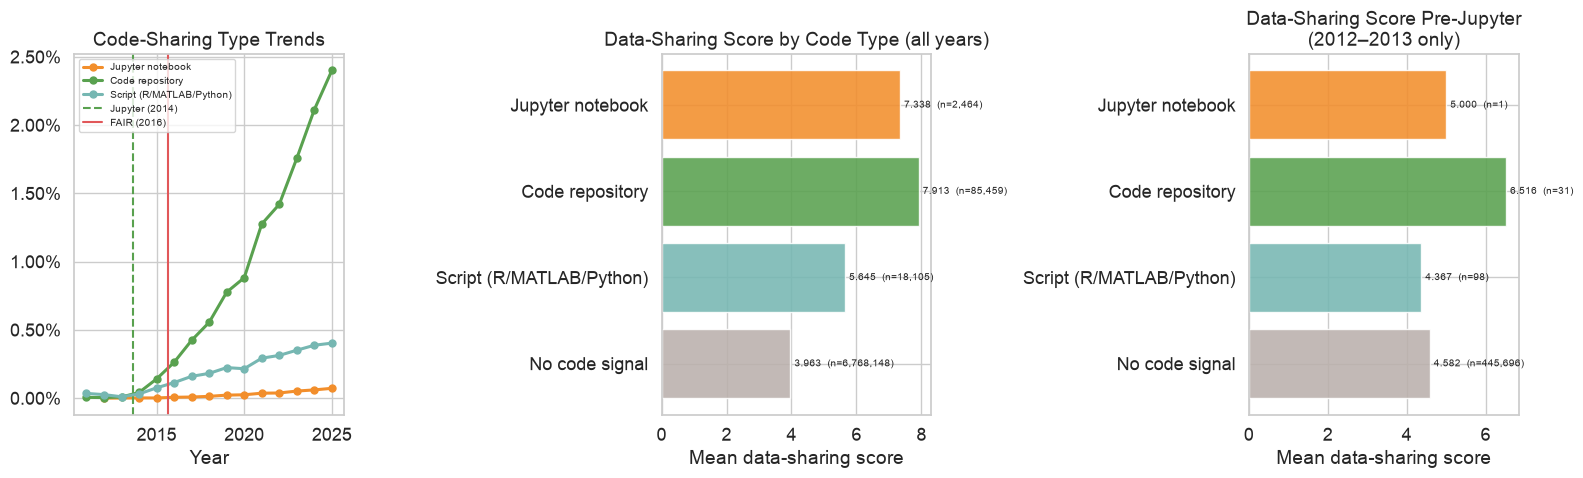

In [8]:
yr_ct = (df.groupby(['year','code_type']).size()
         .reset_index(name='n').merge(yr[['year','n_total']], on='year'))
yr_ct['pct'] = yr_ct['n'] / yr_ct['n_total'] * 100

fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H))

ax = axes[0]
for ct, clr in zip(CT_ORDER[:3], CT_CLRS[:3]):
    sub = yr_ct[yr_ct['code_type'] == ct]
    ax.plot(sub['year'], sub['pct'], lw=2.2, marker='o', ms=5, color=clr, label=ct)
for x, c, ls, lbl in MILESTONES[:2]:
    ax.axvline(x, color=c, lw=1.5, ls=ls, label=lbl)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Code-Sharing Type Trends'); ax.set_xlabel('Year'); ax.legend(fontsize=7)

ax = axes[1]
ct_score = (df.groupby('code_type')['data_sharing_score']
           .agg(mean='mean', n='count').reindex(CT_ORDER).reset_index())
bars = ax.barh(CT_ORDER[::-1], ct_score['mean'][::-1], color=CT_CLRS[::-1],
               alpha=0.88, edgecolor='white')
ax.bar_label(bars,
             labels=[f'{m:.3f}  (n={int(n):,})'
                     for m, n in zip(ct_score['mean'][::-1], ct_score['n'][::-1])],
             padding=3, fontsize=7.5)
ax.set_xlabel('Mean data-sharing score')
ax.set_title('Data-Sharing Score by Code Type (all years)')

ax = axes[2]
pre_jup = df[df['year'] < JUPYTER_YEAR]
ct_pj   = (pre_jup.groupby('code_type')['data_sharing_score']
           .agg(mean='mean', n='count').reindex(CT_ORDER).reset_index())
bars2 = ax.barh(CT_ORDER[::-1], ct_pj['mean'][::-1], color=CT_CLRS[::-1],
                alpha=0.88, edgecolor='white')
ax.bar_label(bars2,
             labels=[f'{m:.3f}  (n={int(n):,})' if pd.notna(m) else f'n/a  (n={int(n):,})'
                     for m, n in zip(ct_pj['mean'][::-1], ct_pj['n'][::-1])],
             padding=3, fontsize=7.5)
ax.set_xlabel('Mean data-sharing score')
ax.set_title(f'Data-Sharing Score Pre-Jupyter\n(2012–{JUPYTER_YEAR-1} only)')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_nb_03_pre_jupyter.png", **SAVEFIG_KWARGS)
plt.show()


---
## §4 — Data-Sharing Score Uplift: Violin + Mann-Whitney + Era Breakdown

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H + 1))

ax = axes[0]
vdata = [df[df['nb_grp'] == g]['data_sharing_score'].dropna().values for g in G_ORDER]
valid = [(i, d) for i, d in enumerate(vdata) if len(d) >= 2]
if valid:
    idx, vd = zip(*valid)
    parts = ax.violinplot(list(vd), positions=list(idx), showmedians=True, showextrema=False)
    for pc, c in zip(parts['bodies'], [G_CLRS[i] for i in idx]):
        pc.set_facecolor(c); pc.set_alpha(0.75)
    parts['cmedians'].set_color('white'); parts['cmedians'].set_linewidth(2)
    for i, d in valid:
        ax.errorbar(i, np.mean(d), yerr=1.96*np.std(d)/len(d)**0.5,
                    fmt='D', color='black', ms=5, capsize=4, zorder=5)
ax.set_xticks(range(len(G_ORDER)))
ax.set_xticklabels(G_ORDER, fontsize=8, rotation=12)
ax.set_ylabel('data-sharing score (0-10)')
ax.set_title('Data-Sharing Score Distribution\n(violin + 95% CI on mean)')

ax = axes[1]
era_grp = (df.groupby(['era','nb_grp'])['data_sharing_score']
           .mean().unstack().reindex(ERA_ORDER)[G_ORDER].reset_index())
x = np.arange(len(ERA_ORDER)); w = 0.26
for k, (col, clr) in enumerate(zip(G_ORDER, G_CLRS)):
    if col in era_grp.columns:
        b = ax.bar(x + (k-1)*w, era_grp[col], width=w, color=clr,
                   alpha=0.88, edgecolor='white', label=col)
        ax.bar_label(b, fmt='{:.2f}', padding=2, fontsize=6.5)
ax.set_xticks(x)
ax.set_xticklabels(ERA_ORDER, rotation=18, ha='right', fontsize=7.5)
ax.set_ylabel('Mean data-sharing score'); ax.set_title('Mean Score by Era × Group')
ax.legend(fontsize=7.5)

sc_nb = df[ df['has_notebook']                        ]['data_sharing_score'].dropna()
sc_cr = df[ df['has_code_repo'] & ~df['has_notebook'] ]['data_sharing_score'].dropna()
sc_nc = df[~df['has_any_code']                        ]['data_sharing_score'].dropna()
ax = axes[2]
bars = ax.barh(G_ORDER[::-1], [sc_nb.mean(), sc_cr.mean(), sc_nc.mean()][::-1],
               color=G_CLRS[::-1], alpha=0.88, edgecolor='white')
ax.bar_label(bars, fmt='{:.4f}', padding=3, fontsize=9)
ax.set_xlabel('Mean data-sharing score'); ax.set_title('Mean Data-Sharing Score by Group')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_nb_04_fair_uplift.png", **SAVEFIG_KWARGS)
plt.show()

print('Mann-Whitney U tests (two-sided):')
for lbl, a, b in [('Notebook  vs No-code  ', sc_nb, sc_nc),
                   ('Code-repo vs No-code  ', sc_cr, sc_nc),
                   ('Notebook  vs Code-repo', sc_nb, sc_cr)]:
    if len(a) >= 2 and len(b) >= 2:
        u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
        # u/(n1*n2) is CLES, not rank-biserial r (CLES=0.5 is the null point).
        # True rank-biserial r = 2*CLES - 1; see 06_gender_analysis.ipynb.
        cles = u / (len(a) * len(b))
        r    = 2 * cles - 1
        sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
        print(f'  {lbl}  Δ={a.mean()-b.mean():+.4f}  p={p:.2e}  r={r:.3f}  {sig}')


---
## §5 — Notebook Platform Evolution

GitHub dominated early; Binder (2016) and Colab (2017) shifted the model from
*static file deposit* to *live executable environment* — a much higher level
of FAIR Reusability.

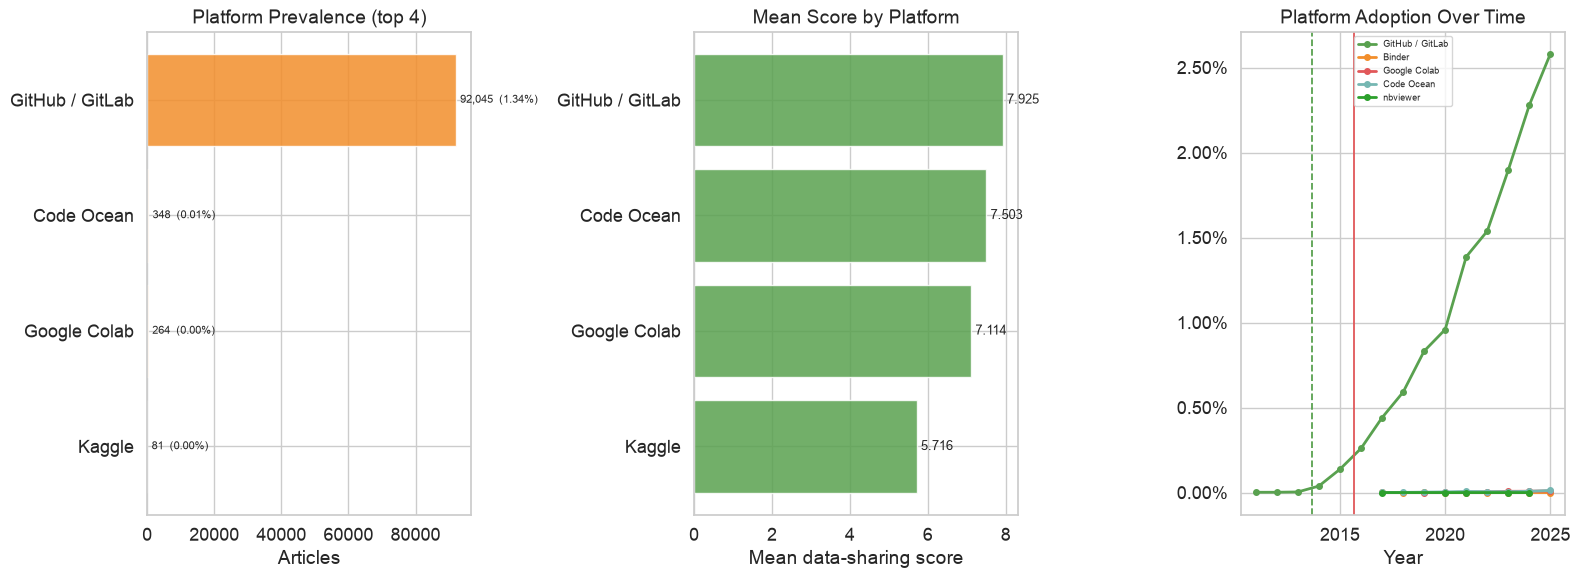

         platform     n   pct  mean_score
  GitHub / GitLab 92045 1.339       7.925
       Code Ocean   348 0.005       7.503
     Google Colab   264 0.004       7.114
           Kaggle    81 0.001       5.716
Zenodo (notebook)    41 0.001       8.537
           Binder    21 0.000       7.571
         nbviewer     5 0.000       8.000
         Deepnote     1 0.000       8.000


In [10]:
df_all_txt = qdb("""SELECT da.article_id, COALESCE(da.statement,'') AS das_text,
                         COALESCE(dl.url,'') AS url
                  FROM data_availability da
                  LEFT JOIN da_link dl ON dl.da_id = da.da_id""")
df_all_txt = df_all_txt.merge(df[['article_id','data_sharing_score','year']], on='article_id', how='left')

plat_rows, plat_yr = [], {}
for platform, pat in PLATFORM_PATTERNS:
    mask = (df_all_txt['das_text'].apply(lambda t: bool(pat.search(t))) |
            df_all_txt['url'].apply(lambda u: bool(pat.search(u))))
    arts = df_all_txt[mask]['article_id'].unique()
    sub  = df[df['article_id'].isin(arts)]
    plat_rows.append({'platform': platform, 'n': len(sub),
                      'mean_score': sub['data_sharing_score'].mean(), 'pct': len(sub)/len(df)*100})
    py = df_all_txt[mask][['article_id','year']].drop_duplicates().merge(
         yr[['year','n_total']], on='year')
    py2 = py.groupby('year').agg(n=('article_id','count'), nt=('n_total','first'))
    py2['pct'] = py2['n'] / py2['nt'] * 100
    plat_yr[platform] = py2
df_plat = pd.DataFrame(plat_rows).sort_values('n', ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H + 1))

ax = axes[0]
top4 = df_plat.head(4)
bars = ax.barh(top4['platform'][::-1], top4['n'][::-1], color=C_NB, alpha=0.85, edgecolor='white')
ax.bar_label(bars, labels=[f'{int(n):,}  ({p:.2f}%)'
             for n, p in zip(top4['n'][::-1], top4['pct'][::-1])], padding=3, fontsize=8)
ax.set_xlabel('Articles'); ax.set_title('Platform Prevalence (top 4)')

ax = axes[1]
bars2 = ax.barh(top4['platform'][::-1], top4['mean_score'][::-1],
                color=C_CODE, alpha=0.85, edgecolor='white')
ax.bar_label(bars2, fmt='{:.3f}', padding=3, fontsize=9)
ax.set_xlabel('Mean data-sharing score'); ax.set_title('Mean Score by Platform')

ax = axes[2]
for (plat, _), clr in zip(PLATFORM_PATTERNS[:5], [C_CODE,C_NB,C_POST,C_SCRP,C_COMP]):
    if plat in plat_yr and len(plat_yr[plat]) >= 2:
        py = plat_yr[plat]
        ax.plot(py.index, py['pct'], lw=2, marker='o', ms=4, color=clr, label=plat[:15])
for x, c, ls, _ in MILESTONES[:2]:
    ax.axvline(x, color=c, lw=1.3, ls=ls)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Platform Adoption Over Time'); ax.set_xlabel('Year'); ax.legend(fontsize=6.5)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_nb_05_platforms.png", **SAVEFIG_KWARGS)
plt.show()
print(df_plat[['platform','n','pct','mean_score']].round(3).to_string(index=False))


---
## §6 — Repository Tier: Persistent DOI vs Ephemeral Host

FAIR *Findable* requires a persistent identifier. Zenodo/Figshare/OSF/Dryad
mint DOIs; GitHub does not by default. Do authors who share notebooks also
tend to choose more persistent hosting?

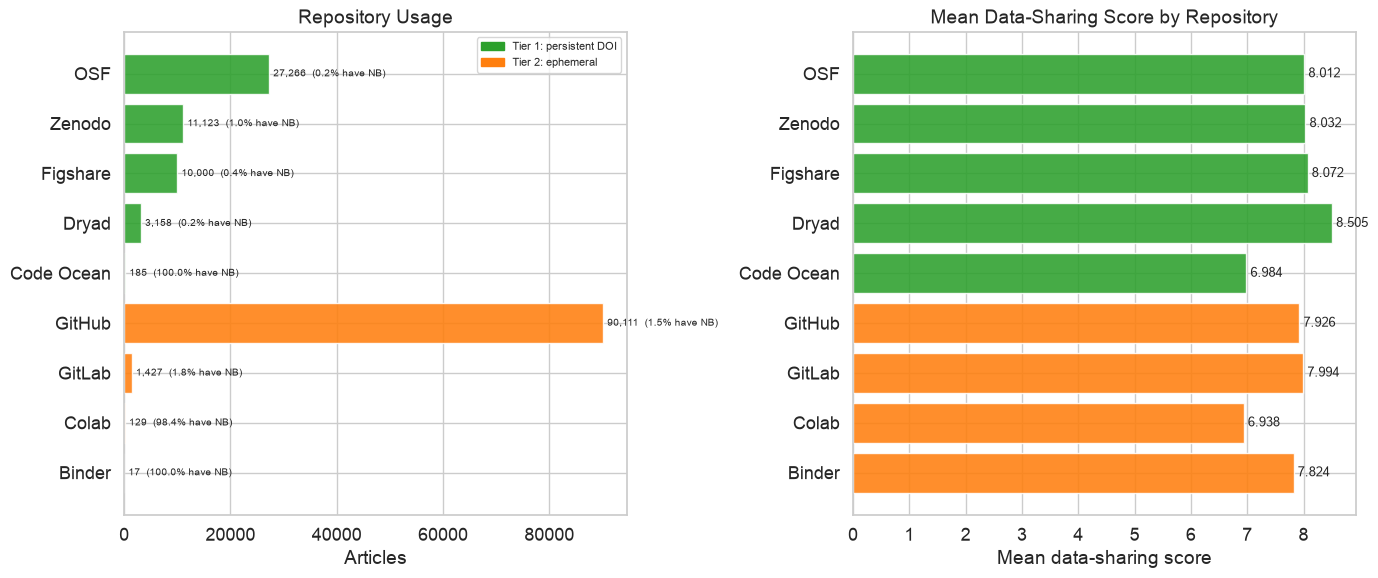

      repo  tier     n  nb_rate  mean_score
       OSF     1 27266     0.20        8.01
    Zenodo     1 11123     0.97        8.03
  Figshare     1 10000     0.37        8.07
     Dryad     1  3158     0.22        8.51
Code Ocean     1   185   100.00        6.98
    GitHub     2 90111     1.53        7.93
    GitLab     2  1427     1.75        7.99
     Colab     2   129    98.45        6.94
    Binder     2    17   100.00        7.82


In [11]:
REPO_TIERS = [
    ('Zenodo',     re.compile(r'zenodo\.org',    re.I), 1),
    ('Figshare',   re.compile(r'figshare\.com',  re.I), 1),
    ('OSF',        re.compile(r'osf\.io',        re.I), 1),
    ('Code Ocean', re.compile(r'codeocean\.com', re.I), 1),
    ('Dryad',      re.compile(r'datadryad\.org', re.I), 1),
    ('GitHub',     re.compile(r'github\.com',    re.I), 2),
    ('GitLab',     re.compile(r'gitlab\.com',    re.I), 2),
    ('Binder',     re.compile(r'mybinder\.org',  re.I), 2),
    ('Colab',      re.compile(r'colab\.',         re.I), 2),
]
df_urls2 = qdb("""SELECT da.article_id, COALESCE(dl.url,'') AS url
              FROM data_availability da JOIN da_link dl ON dl.da_id = da.da_id""")
df_urls2 = df_urls2.merge(df[['article_id','has_notebook','data_sharing_score']], on='article_id', how='left')

repo_rows = []
for name, pat, tier in REPO_TIERS:
    mask = df_urls2['url'].apply(lambda u: bool(pat.search(u)) if u else False)
    sub  = df[df['article_id'].isin(df_urls2[mask]['article_id'].unique())]
    repo_rows.append({'repo': name, 'tier': tier, 'n': len(sub),
                      'nb_rate': sub['has_notebook'].mean()*100,
                      'mean_score': sub['data_sharing_score'].mean()})
df_repo = pd.DataFrame(repo_rows).sort_values(['tier','n'], ascending=[True,False])
tier_clrs = ['#2ca02c' if t==1 else '#ff7f0e' for t in df_repo['tier']]

fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H + 1))

ax = axes[0]
bars = ax.barh(df_repo['repo'][::-1], df_repo['n'][::-1],
               color=tier_clrs[::-1], alpha=0.88, edgecolor='white')
ax.bar_label(bars, labels=[f'{int(n):,}  ({r:.1f}% have NB)'
             for n, r in zip(df_repo['n'][::-1], df_repo['nb_rate'][::-1])],
             padding=3, fontsize=7.5)
ax.set_xlabel('Articles')
ax.set_title('Repository Usage')
ax.legend(handles=[mpatches.Patch(color='#2ca02c', label='Tier 1: persistent DOI'),
                   mpatches.Patch(color='#ff7f0e', label='Tier 2: ephemeral')], fontsize=8)

ax = axes[1]
bars2 = ax.barh(df_repo['repo'][::-1], df_repo['mean_score'][::-1],
                color=tier_clrs[::-1], alpha=0.88, edgecolor='white')
ax.bar_label(bars2, fmt='{:.3f}', padding=3, fontsize=9)
ax.set_xlabel('Mean data-sharing score'); ax.set_title('Mean Data-Sharing Score by Repository')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_nb_06_repo_tier.png", **SAVEFIG_KWARGS)
plt.show()
print(df_repo.round(2).to_string(index=False))


---
## §7 — DAS Quality Signals Co-occurring with Notebooks

Do notebook-sharing papers write richer DAS? We compare five structured
quality signals, DAS verbosity (word count, sentence count), and the
distribution of DAS categories across code groups.

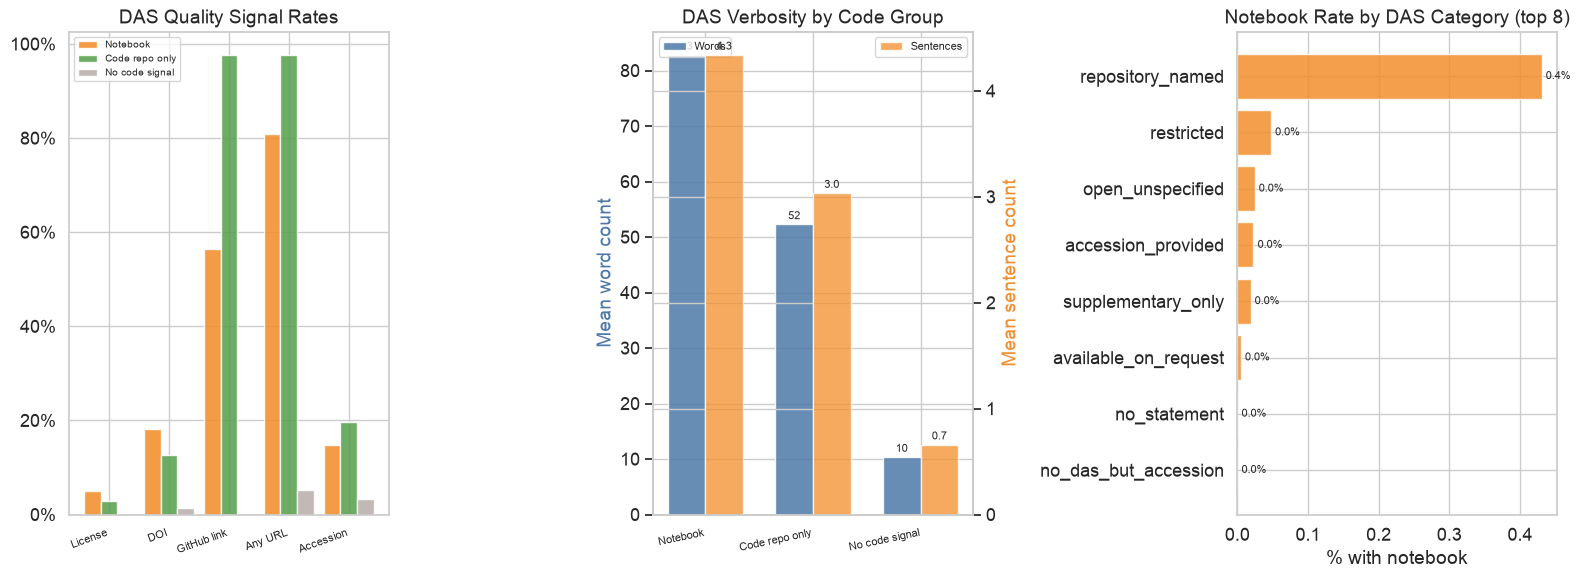

In [12]:
SIG_COLS = ['mentions_license','mentions_doi','mentions_github','has_url','has_accession']
SIG_LBLS = {'mentions_license':'License','mentions_doi':'DOI',
            'mentions_github':'GitHub link','has_url':'Any URL','has_accession':'Accession'}
sig_grp = (df.groupby('nb_grp')[SIG_COLS + ['das_words','das_sents']]
           .mean().reindex(G_ORDER))
sig_pct = sig_grp[SIG_COLS] * 100

fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H + 1))

ax = axes[0]
x = np.arange(len(SIG_COLS)); w = 0.28
for k, (grp, clr) in enumerate(zip(G_ORDER, G_CLRS)):
    ax.bar(x + (k-1)*w, [sig_pct.loc[grp, c] for c in SIG_COLS],
           width=w, color=clr, alpha=0.88, label=grp, edgecolor='white')
ax.set_xticks(x)
ax.set_xticklabels([SIG_LBLS[c] for c in SIG_COLS], rotation=20, ha='right', fontsize=8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('DAS Quality Signal Rates'); ax.legend(fontsize=7)

ax = axes[1]
grp_verb = sig_grp[['das_words','das_sents']].reset_index()
x2 = np.arange(len(G_ORDER)); w2 = 0.35
b1 = ax.bar(x2 - w2/2, grp_verb['das_words'], width=w2, color=C_PRE, alpha=0.85, label='Words')
ax.bar_label(b1, fmt='{:.0f}', padding=2, fontsize=8)
ax2r = ax.twinx()
b2 = ax2r.bar(x2 + w2/2, grp_verb['das_sents'], width=w2, color=C_NB, alpha=0.75, label='Sentences')
ax2r.bar_label(b2, fmt='{:.1f}', padding=2, fontsize=8)
ax.set_xticks(x2); ax.set_xticklabels(G_ORDER, rotation=12, ha='right', fontsize=8)
ax.set_ylabel('Mean word count', color=C_PRE); ax2r.set_ylabel('Mean sentence count', color=C_NB)
ax.set_title('DAS Verbosity by Code Group')
ax.legend(loc='upper left', fontsize=8); ax2r.legend(loc='upper right', fontsize=8)

ax = axes[2]
cat_nb = (df.groupby('das_cat').agg(n=('article_id','count'), nb=('has_notebook','sum')).reset_index())
cat_nb['pct_nb'] = cat_nb['nb'] / cat_nb['n'] * 100
cat_nb = cat_nb.sort_values('pct_nb', ascending=False).head(8)
bars3 = ax.barh(cat_nb['das_cat'][::-1], cat_nb['pct_nb'][::-1],
                color=C_NB, alpha=0.85, edgecolor='white')
ax.bar_label(bars3, fmt='{:.1f}%', padding=3, fontsize=8)
ax.set_xlabel('% with notebook'); ax.set_title('Notebook Rate by DAS Category (top 8)')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_nb_07_quality.png", **SAVEFIG_KWARGS)
plt.show()


---
## §8 — DAS Text Vocabulary: Language of Computational Reproducibility

15 keyword patterns extracted from DAS text, measuring prevalence and
correlation with both notebook sharing and overall data-sharing score.

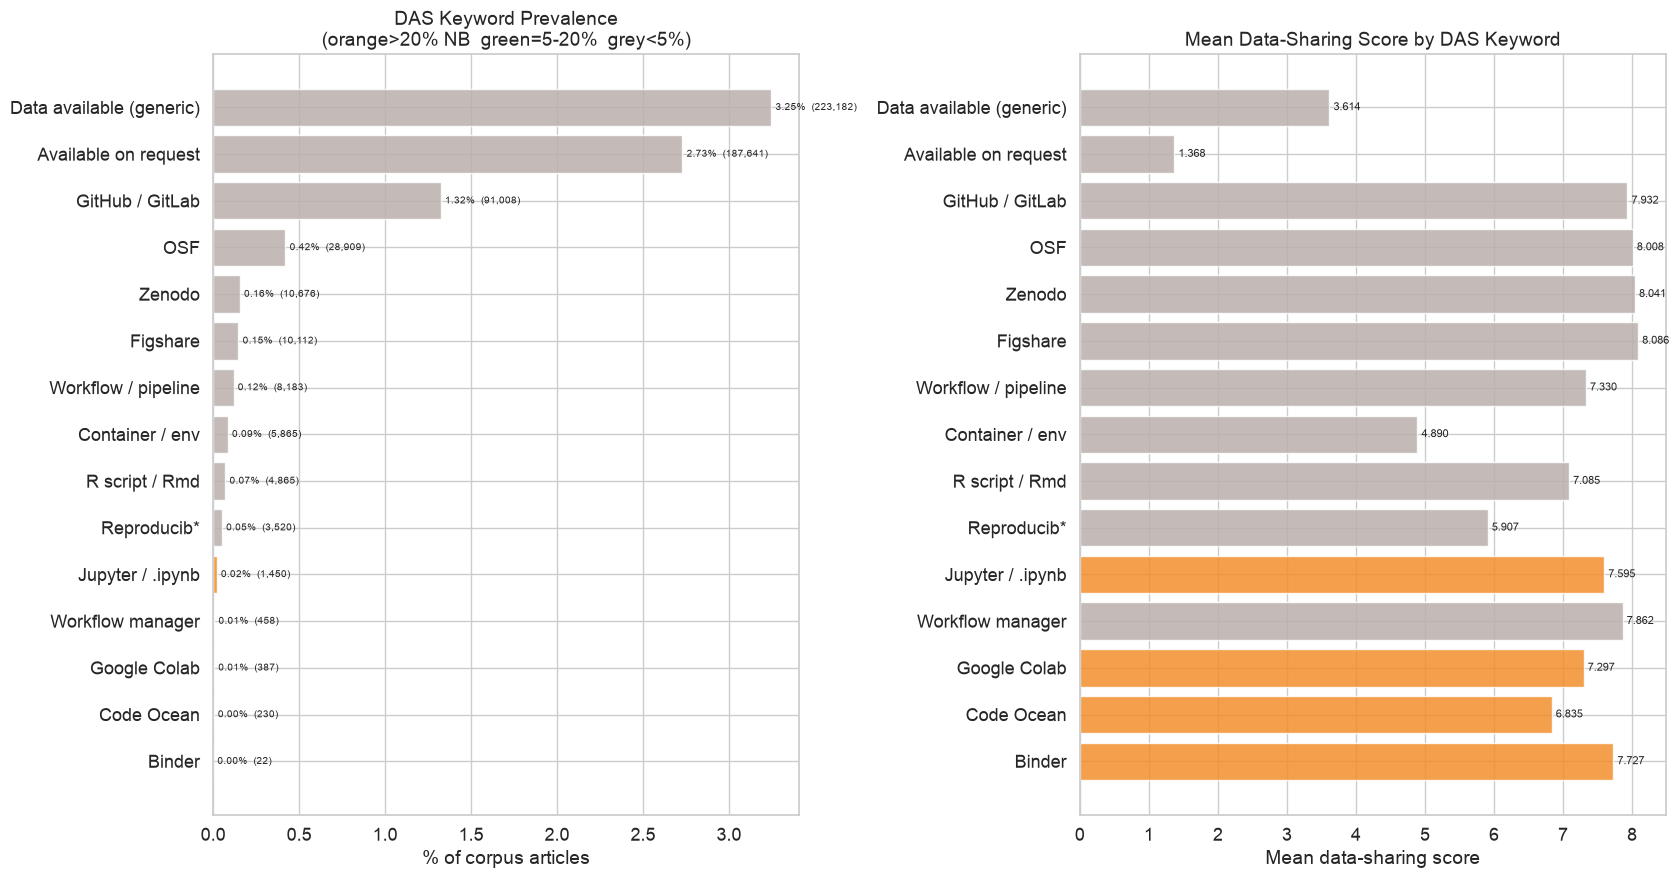

                 keyword      n   pct  nb_rate  mean_score
Data available (generic) 223182 3.247    0.088       3.614
    Available on request 187641 2.730    0.006       1.368
         GitHub / GitLab  91008 1.324    1.526       7.932
                     OSF  28909 0.421    0.197       8.008
                  Zenodo  10676 0.155    1.002       8.041
                Figshare  10112 0.147    0.356       8.086
     Workflow / pipeline   8183 0.119    2.579       7.330
         Container / env   5865 0.085    1.432       4.890
          R script / Rmd   4865 0.071    0.843       7.085
             Reproducib*   3520 0.051    3.892       5.907
        Jupyter / .ipynb   1450 0.021   99.517       7.595
        Workflow manager    458 0.007    3.493       7.862
            Google Colab    387 0.006   69.509       7.297
              Code Ocean    230 0.003   80.870       6.835
                  Binder     22 0.000  100.000       7.727


In [13]:
VOCAB = [
    (r'jupyter|ipynb',              'Jupyter / .ipynb'),
    (r'github\.com|gitlab\.com',    'GitHub / GitLab'),
    (r'zenodo\.org',                'Zenodo'),
    (r'mybinder|binder\.',          'Binder'),
    (r'colab',                      'Google Colab'),
    (r'codeocean',                  'Code Ocean'),
    (r'reproducib',                 'Reproducib*'),
    (r'workflow|pipeline',          'Workflow / pipeline'),
    (r'docker|singularity|conda',   'Container / env'),
    (r'snakemake|nextflow|cwl',     'Workflow manager'),
    (r'r\s+script|\.rmd\b',        'R script / Rmd'),
    (r'figshare\.com',              'Figshare'),
    (r'osf\.io',                    'OSF'),
    (r'available\s+on\s+request',   'Available on request'),
    (r'data\s+(?:are\s+)?available','Data available (generic)'),
]
kw_rows = []
for pat_str, label in VOCAB:
    pat  = re.compile(pat_str, re.I)
    mask = df_das['das_text'].apply(lambda t: bool(pat.search(str(t))) if t else False)
    sub  = df[df['article_id'].isin(set(df_das[mask]['article_id']))]
    kw_rows.append({'keyword': label, 'n': len(sub), 'pct': len(sub)/len(df)*100,
                    'nb_rate': sub['has_notebook'].mean()*100 if len(sub) > 0 else 0,
                    'mean_score': sub['data_sharing_score'].mean() if len(sub) > 0 else float('nan')})
df_kw = pd.DataFrame(kw_rows).sort_values('n', ascending=False)

def kw_clr(r): return C_NB if r > 20 else (C_CODE if r > 5 else C_NONE)
kw_clrs = [kw_clr(r) for r in df_kw['nb_rate'][::-1]]

fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 3, FIG_H + 4))

ax = axes[0]
bars = ax.barh(df_kw['keyword'][::-1], df_kw['pct'][::-1], color=kw_clrs, alpha=0.85, edgecolor='white')
ax.bar_label(bars, labels=[f'{p:.2f}%  ({int(n):,})'
             for p, n in zip(df_kw['pct'][::-1], df_kw['n'][::-1])], padding=3, fontsize=7.5)
ax.set_xlabel('% of corpus articles')
ax.set_title('DAS Keyword Prevalence\n(orange>20% NB  green=5-20%  grey<5%)')

ax = axes[1]
bars2 = ax.barh(df_kw['keyword'][::-1], df_kw['mean_score'][::-1],
                color=kw_clrs, alpha=0.85, edgecolor='white')
ax.bar_label(bars2, fmt='{:.3f}', padding=3, fontsize=8)
ax.set_xlabel('Mean data-sharing score'); ax.set_title('Mean Data-Sharing Score by DAS Keyword')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_nb_08_vocabulary.png", **SAVEFIG_KWARGS)
plt.show()
print(df_kw.round(3).to_string(index=False))


---
## §9 — JATS4R DAS Compliance × Notebook Sharing

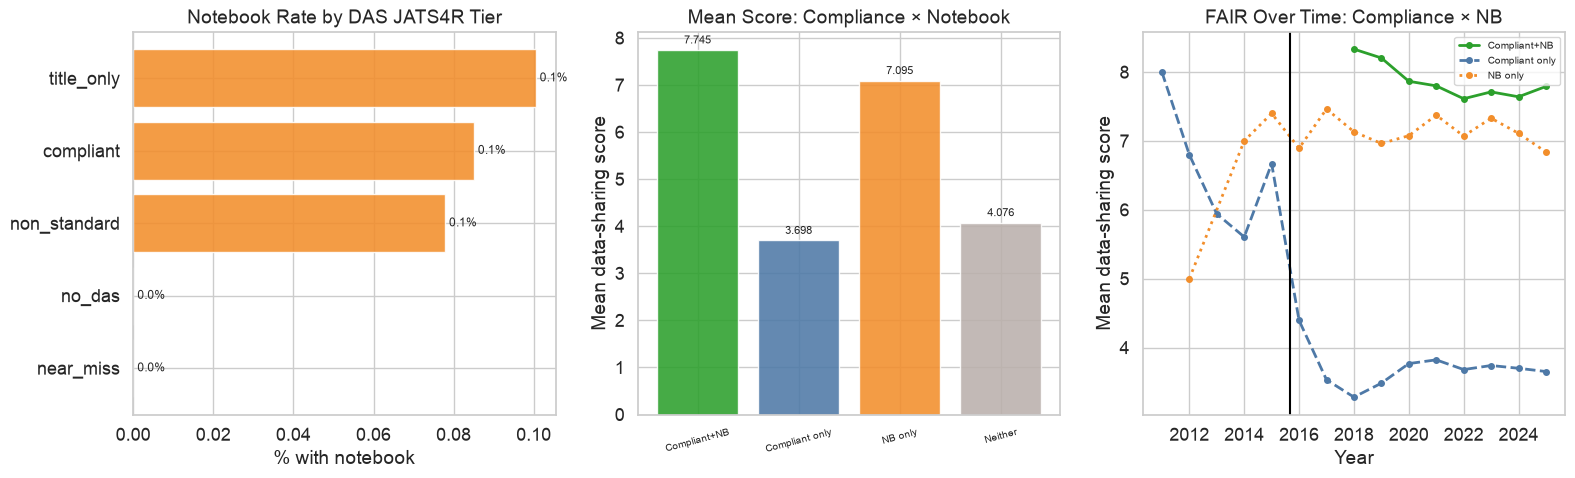

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H))

ax = axes[0]
tier_agg = (df.groupby('das_tier').agg(n=('article_id','count'),
    nb_rate=('has_notebook', lambda x: x.mean()*100),
    mean_score=('data_sharing_score','mean')).reset_index().sort_values('nb_rate', ascending=False))
bars = ax.barh(tier_agg['das_tier'][::-1], tier_agg['nb_rate'][::-1],
               color=C_NB, alpha=0.88, edgecolor='white')
ax.bar_label(bars, fmt='{:.1f}%', padding=3, fontsize=8.5)
ax.set_xlabel('% with notebook'); ax.set_title('Notebook Rate by DAS JATS4R Tier')

ax = axes[1]
grp22 = {'Compliant+NB':  df[ df['das_compliant'] &  df['has_notebook']]['data_sharing_score'].dropna(),
          'Compliant only':df[ df['das_compliant'] & ~df['has_notebook']]['data_sharing_score'].dropna(),
          'NB only':       df[~df['das_compliant'] &  df['has_notebook']]['data_sharing_score'].dropna(),
          'Neither':       df[~df['das_compliant'] & ~df['has_notebook']]['data_sharing_score'].dropna()}
bars2 = ax.bar(list(grp22), [v.mean() if len(v)>=2 else 0 for v in grp22.values()],
               color=[C_COMP,C_PRE,C_NB,C_NONE], alpha=0.88, edgecolor='white')
ax.bar_label(bars2, fmt='{:.3f}', padding=3, fontsize=8)
ax.set_ylabel('Mean data-sharing score'); ax.set_title('Mean Score: Compliance × Notebook')
ax.tick_params(axis='x', labelsize=7, rotation=15)

ax = axes[2]
for flag, lbl, clr, ls in [
        (df['das_compliant'] &  df['has_notebook'], 'Compliant+NB',   C_COMP, '-'),
        (df['das_compliant'] & ~df['has_notebook'], 'Compliant only', C_PRE,  '--'),
        (~df['das_compliant'] & df['has_notebook'], 'NB only',        C_NB,   ':')]:
    sub_yr = df[flag].groupby('year')['data_sharing_score'].mean()
    if len(sub_yr) >= 2:
        ax.plot(sub_yr.index, sub_yr.values, lw=2, marker='o', ms=4, color=clr, ls=ls, label=lbl)
ax.axvline(FAIR_YEAR - 0.33, color='black', lw=1.5, ls='-')
ax.set_ylabel('Mean data-sharing score'); ax.set_title('FAIR Over Time: Compliance × NB')
ax.legend(fontsize=7.5); ax.set_xlabel('Year')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_nb_09_jats4r.png", **SAVEFIG_KWARGS)
plt.show()


---
## §10 — Author Count × Notebook Sharing  *(NEW)*

**Hypothesis:** more collaborative papers (larger author teams) are more likely
to share notebooks, because multi-person computational projects naturally produce
shareable pipelines. We test this at the article level and by era.

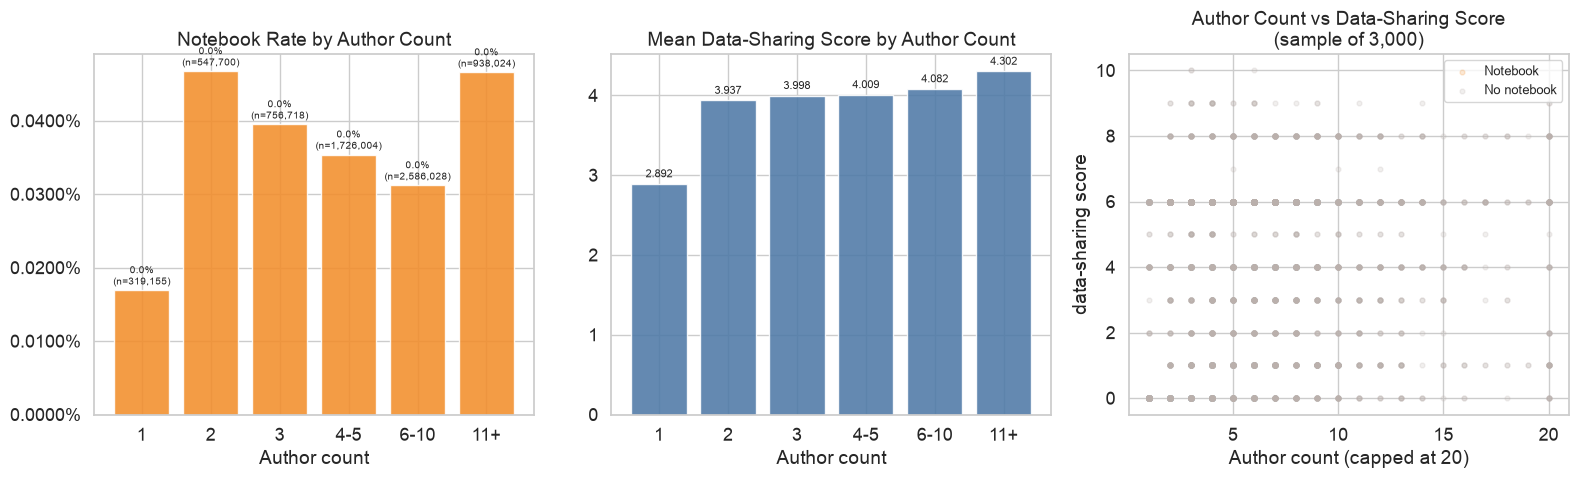

Pearson r (n_authors vs has_notebook): 0.0025  p=9.40e-11


Mann-Whitney (author count, NB vs no-NB): p=1.94e-01
Mean authors — with NB: 7.75


Mean authors — no NB  : 6.97


In [15]:
# Author count per article
df_auth = qdb("""SELECT article_id, COUNT(*) AS n_authors
              FROM article_author GROUP BY article_id""")
df = df.merge(df_auth, on='article_id', how='left')
df['n_authors'] = df['n_authors'].fillna(1).astype(int)

# Bin author counts
df['auth_bin'] = pd.cut(df['n_authors'],
    bins=[0,1,2,3,5,10,999],
    labels=['1','2','3','4-5','6-10','11+'])

auth_agg = (df.groupby('auth_bin', observed=True).agg(
    n         = ('article_id','count'),
    nb_rate   = ('has_notebook', lambda x: x.mean()*100),
    mean_score = ('data_sharing_score','mean'),
).reset_index())

fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H))

ax = axes[0]
bars = ax.bar(auth_agg['auth_bin'].astype(str), auth_agg['nb_rate'],
              color=C_NB, alpha=0.88, edgecolor='white')
ax.bar_label(bars, labels=[f'{r:.1f}%\n(n={int(n):,})'
             for r, n in zip(auth_agg['nb_rate'], auth_agg['n'])], padding=2, fontsize=7.5)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel('Author count'); ax.set_title('Notebook Rate by Author Count')

ax = axes[1]
bars2 = ax.bar(auth_agg['auth_bin'].astype(str), auth_agg['mean_score'],
               color=C_PRE, alpha=0.88, edgecolor='white')
ax.bar_label(bars2, fmt='{:.3f}', padding=3, fontsize=8)
ax.set_xlabel('Author count'); ax.set_title('Mean Data-Sharing Score by Author Count')

ax = axes[2]
# Correlation scatter: n_authors vs data_sharing_score, coloured by has_notebook
sample = df.dropna(subset=['n_authors','data_sharing_score']).sample(min(3000, len(df)), random_state=42)
for has_nb, clr, lbl in [(True,C_NB,'Notebook'),(False,C_NONE,'No notebook')]:
    sub = sample[sample['has_notebook'] == has_nb]
    ax.scatter(sub['n_authors'].clip(upper=20), sub['data_sharing_score'],
               alpha=0.2, s=12, color=clr, label=lbl)
ax.set_xlabel('Author count (capped at 20)'); ax.set_ylabel('data-sharing score')
ax.set_title('Author Count vs Data-Sharing Score\n(sample of 3,000)')
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_nb_10_authors.png", **SAVEFIG_KWARGS)
plt.show()

# Correlation test
r, p = stats.pearsonr(df['n_authors'].clip(upper=50),
                      df['has_notebook'].astype(float))
print(f'Pearson r (n_authors vs has_notebook): {r:.4f}  p={p:.2e}')
u, p2 = stats.mannwhitneyu(df[df['has_notebook']]['n_authors'],
                            df[~df['has_notebook']]['n_authors'],
                            alternative='two-sided')
print(f'Mann-Whitney (author count, NB vs no-NB): p={p2:.2e}')
print(f'Mean authors — with NB: {df[df["has_notebook"]]["n_authors"].mean():.2f}')
print(f'Mean authors — no NB  : {df[~df["has_notebook"]]["n_authors"].mean():.2f}')


---
## §11 — Data-Sharing Score Quartile Analysis  *(NEW)*

Are notebooks concentrated in already-high-scoring papers (luxury good)
or are they the primary *driver* of data-sharing score elevation?
We split the corpus into FAIR-score quartiles and measure notebook rates
within each quartile, then track quartile membership over the four eras.

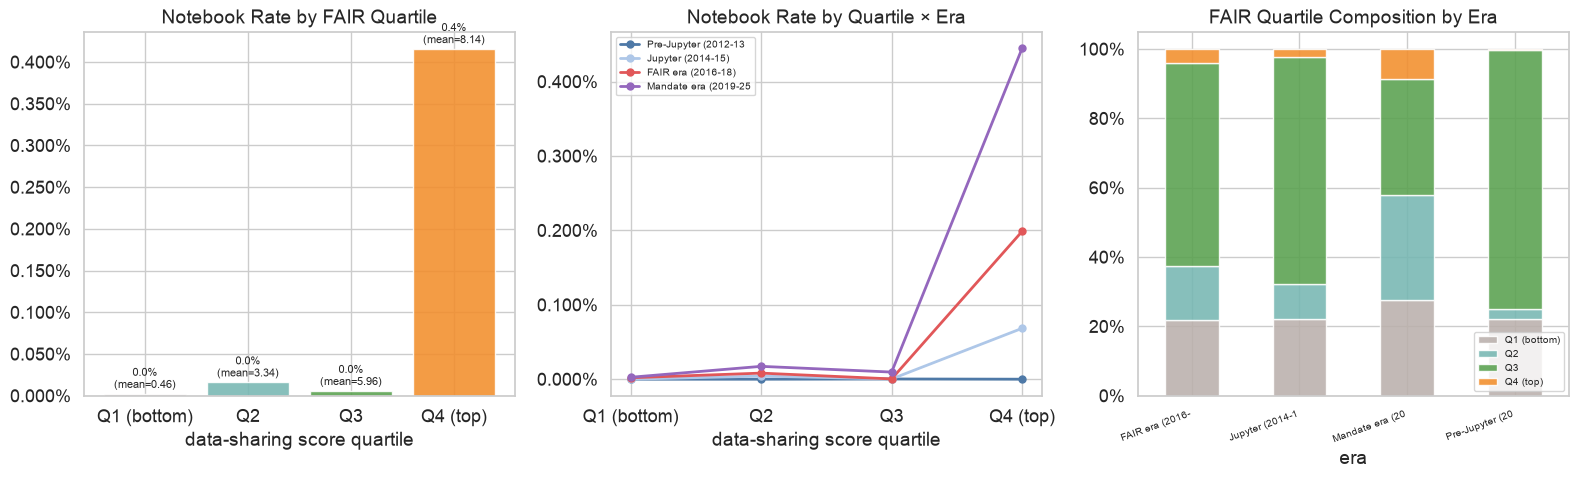

    score_q       n  nb_rate  mean_score  pct_das
Q1 (bottom) 1796029     0.00        0.46    45.93
         Q2 1719457     0.02        3.34    92.09
         Q3 2881215     0.01        5.96     4.34
   Q4 (top)  477475     0.42        8.14   100.00


In [16]:
df['score_q'] = pd.qcut(df['data_sharing_score'], q=4, labels=['Q1 (bottom)','Q2','Q3','Q4 (top)'])

q_agg = (df.groupby('score_q', observed=True).agg(
    n          = ('article_id','count'),
    nb_rate    = ('has_notebook', lambda x: x.mean()*100),
    mean_score  = ('data_sharing_score','mean'),
    pct_das    = ('has_das',  lambda x: x.mean()*100),
).reset_index())

fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H))

ax = axes[0]
bars = ax.bar(q_agg['score_q'].astype(str), q_agg['nb_rate'],
              color=[C_NONE,C_SCRP,C_CODE,C_NB], alpha=0.88, edgecolor='white')
ax.bar_label(bars, labels=[f'{r:.1f}%\n(mean={m:.2f})'
             for r, m in zip(q_agg['nb_rate'], q_agg['mean_score'])], padding=2, fontsize=8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel('data-sharing score quartile'); ax.set_title('Notebook Rate by FAIR Quartile')

ax = axes[1]
# Notebook rate by quartile × era
q_era = (df.groupby(['score_q','era'], observed=True)['has_notebook']
         .mean().unstack() * 100)
for era_lbl, clr in zip(ERA_ORDER, [C_PRE,'#aec7e8',C_POST,C_ETH]):
    if era_lbl in q_era.columns:
        ax.plot(q_era.index.astype(str), q_era[era_lbl], lw=2, marker='o', ms=5,
                color=clr, label=' '.join(era_lbl.split())[:20])
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel('data-sharing score quartile')
ax.set_title('Notebook Rate by Quartile × Era')
ax.legend(fontsize=7)

ax = axes[2]
# Share of each quartile that is in the top data-sharing-score tier now vs was pre-FAIR
era_q = (df.groupby(['era','score_q'], observed=True).size()
         .unstack(fill_value=0))
era_q_pct = era_q.div(era_q.sum(axis=1), axis=0) * 100
era_q_pct.plot(kind='bar', ax=ax, stacked=True,
               color=[C_NONE,C_SCRP,C_CODE,C_NB], alpha=0.88, edgecolor='white')
ax.set_xticklabels([' '.join(e.split())[:15] for e in era_q_pct.index],
                   rotation=20, ha='right', fontsize=7.5)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('FAIR Quartile Composition by Era')
ax.legend(fontsize=7, loc='lower right')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_nb_11_quartiles.png", **SAVEFIG_KWARGS)
plt.show()
print(q_agg[['score_q','n','nb_rate','mean_score','pct_das']].round(2).to_string(index=False))


---
## §12 — Temporal Co-evolution of DAS, Notebooks, and Ethics  *(NEW)*

All three open-science practices were growing simultaneously during the study period.
Do they grow in tandem (driven by the same underlying culture shift) or do
notebooks lag/lead the others? We plot all three normalised adoption curves
on the same axis and compute their pairwise Pearson correlations over time.

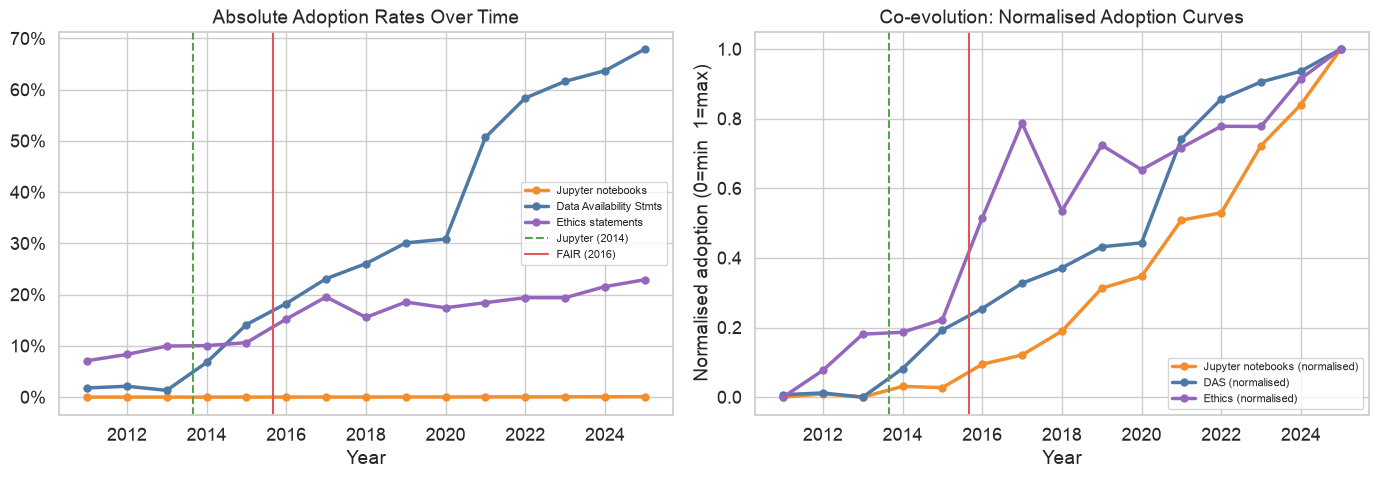

  NB vs DAS:  r = 0.9637  p = 7.85e-09
  NB vs Ethics:  r = 0.8432  p = 7.87e-05
  DAS vs Ethics:  r = 0.8984  p = 5.39e-06


In [17]:
yr_coev = (df.groupby('year').agg(
    pct_nb    = ('has_notebook', lambda x: x.mean()*100),
    pct_das   = ('has_das',     lambda x: x.mean()*100),
    pct_eth   = ('has_ethics',  lambda x: x.mean()*100),
    n         = ('article_id',  'count'),
).reset_index())

# Normalise each to 0-1 range for co-evolution view
for col in ['pct_nb','pct_das','pct_eth']:
    mn, mx = yr_coev[col].min(), yr_coev[col].max()
    yr_coev[col + '_norm'] = (yr_coev[col] - mn) / (mx - mn) if mx > mn else 0

fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))

ax = axes[0]
for col, clr, lbl in [
        ('pct_nb',  C_NB,  'Jupyter notebooks'),
        ('pct_das', C_PRE, 'Data Availability Stmts'),
        ('pct_eth', C_ETH, 'Ethics statements')]:
    ax.plot(yr_coev['year'], yr_coev[col], lw=2.5, marker='o', ms=5, color=clr, label=lbl)
for x, c, ls, lbl in MILESTONES[:2]:
    ax.axvline(x, color=c, lw=1.5, ls=ls, label=lbl)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Absolute Adoption Rates Over Time')
ax.set_xlabel('Year'); ax.legend(fontsize=8)

ax = axes[1]
for col, clr, lbl in [
        ('pct_nb_norm',  C_NB,  'Jupyter notebooks (normalised)'),
        ('pct_das_norm', C_PRE, 'DAS (normalised)'),
        ('pct_eth_norm', C_ETH, 'Ethics (normalised)')]:
    ax.plot(yr_coev['year'], yr_coev[col], lw=2.5, marker='o', ms=5, color=clr, label=lbl)
for x, c, ls, _ in MILESTONES[:2]:
    ax.axvline(x, color=c, lw=1.5, ls=ls)
ax.set_ylabel('Normalised adoption (0=min  1=max)')
ax.set_title('Co-evolution: Normalised Adoption Curves')
ax.set_xlabel('Year'); ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_nb_12_coevolution.png", **SAVEFIG_KWARGS)
plt.show()

# Pairwise correlations
for (a, b, la, lb) in [('pct_nb','pct_das','NB','DAS'),
                        ('pct_nb','pct_eth','NB','Ethics'),
                        ('pct_das','pct_eth','DAS','Ethics')]:
    r, p = stats.pearsonr(yr_coev[a], yr_coev[b])
    print(f'  {la} vs {lb}:  r = {r:.4f}  p = {p:.2e}')


---
## §13 — Keyword Co-occurrence Heatmap  *(NEW)*

Which DAS keywords cluster together? A co-occurrence matrix reveals whether
notebook-sharing language (`jupyter`, `binder`) consistently appears with
reproducibility vocabulary (`reproducib*`, `workflow`) or with specific
platforms (`zenodo`, `github`). This reveals whether there is a coherent
*computational transparency* writing style in DAS text.

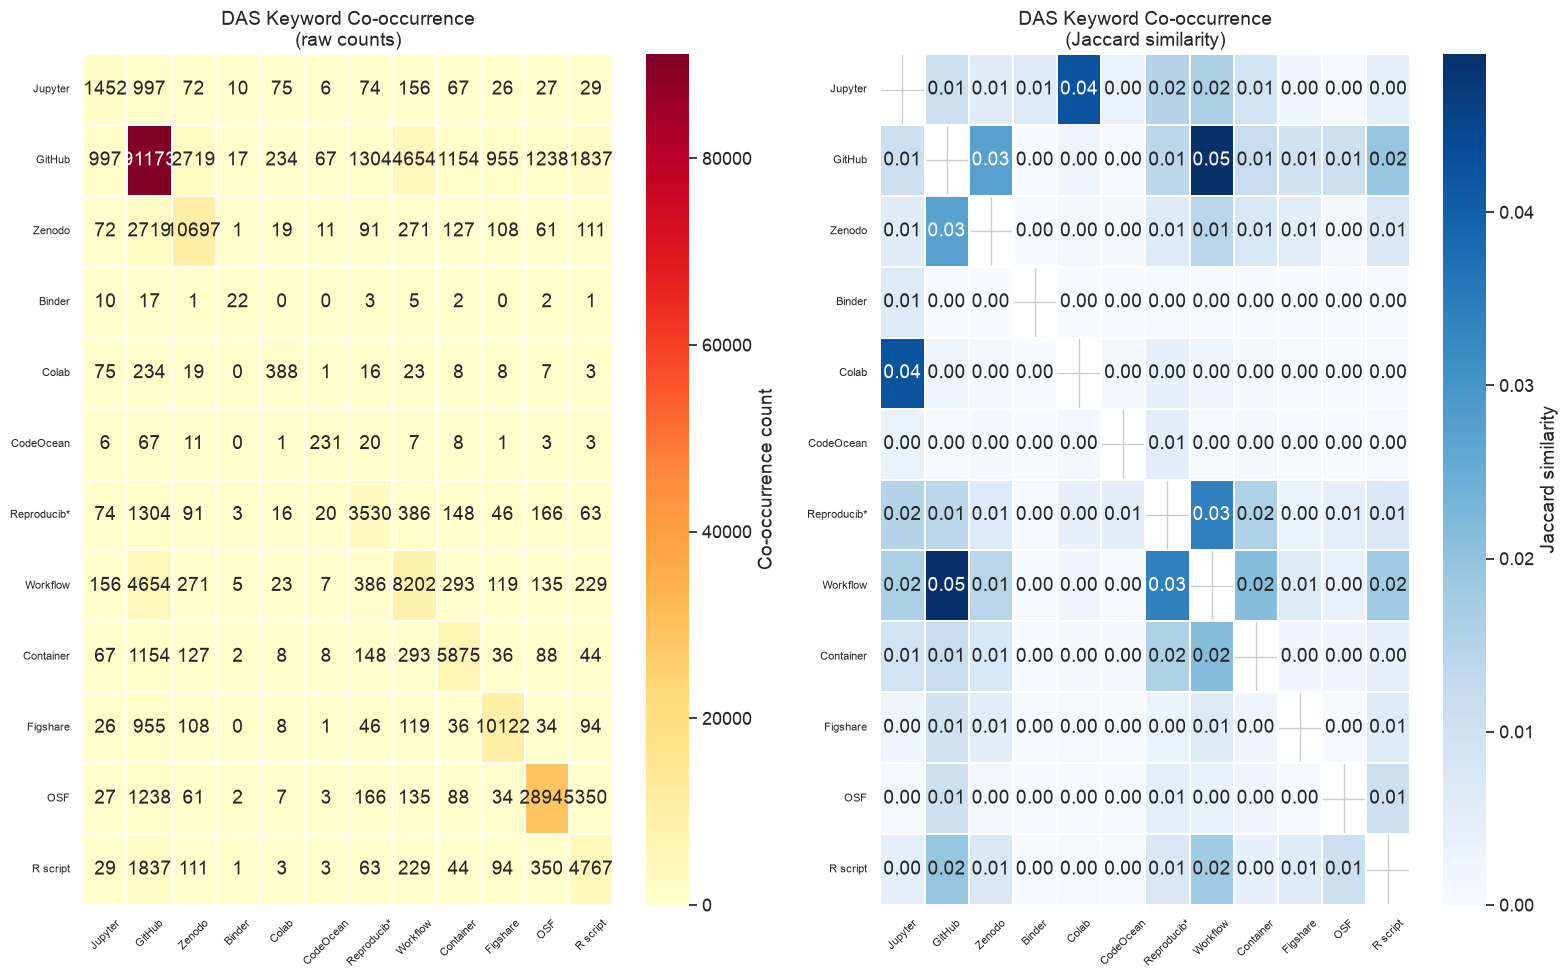

In [18]:
# Use the top-12 keywords for the heatmap (exclude generic ones)
KW_HM = [
    (r'jupyter|ipynb',           'Jupyter'),
    (r'github\.com|gitlab\.com', 'GitHub'),
    (r'zenodo\.org',             'Zenodo'),
    (r'mybinder|binder\.',       'Binder'),
    (r'colab',                   'Colab'),
    (r'codeocean',               'CodeOcean'),
    (r'reproducib',              'Reproducib*'),
    (r'workflow|pipeline',       'Workflow'),
    (r'docker|singularity|conda','Container'),
    (r'figshare\.com',           'Figshare'),
    (r'osf\.io',                 'OSF'),
    (r'r\s+script|\.rmd',    'R script'),
]

# Build binary flags per article
hm_flags = {}
for pat_str, label in KW_HM:
    pat = re.compile(pat_str, re.I)
    mask = df_das['das_text'].apply(lambda t: bool(pat.search(str(t))) if t else False)
    hm_flags[label] = set(df_das[mask]['article_id'])

labels_hm = [l for _, l in KW_HM]
n_hm = len(labels_hm)
cooc = np.zeros((n_hm, n_hm))
for i, la in enumerate(labels_hm):
    for j, lb in enumerate(labels_hm):
        cooc[i, j] = len(hm_flags[la] & hm_flags[lb])

# Normalise to Jaccard similarity
jacc = np.zeros_like(cooc)
for i in range(n_hm):
    for j in range(n_hm):
        union = len(hm_flags[labels_hm[i]] | hm_flags[labels_hm[j]])
        jacc[i, j] = cooc[i, j] / union if union > 0 else 0

fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 2, FIG_H + 5))

ax = axes[0]
sns.heatmap(pd.DataFrame(cooc, index=labels_hm, columns=labels_hm),
            annot=True, fmt='.0f', cmap='YlOrRd', ax=ax,
            linewidths=0.3, cbar_kws={'label': 'Co-occurrence count'})
ax.set_title('DAS Keyword Co-occurrence\n(raw counts)')
ax.tick_params(axis='x', rotation=45, labelsize=8)
ax.tick_params(axis='y', rotation=0,  labelsize=8)

ax = axes[1]
np.fill_diagonal(jacc, np.nan)   # hide self-similarity
sns.heatmap(pd.DataFrame(jacc, index=labels_hm, columns=labels_hm),
            annot=True, fmt='.2f', cmap='Blues', ax=ax,
            linewidths=0.3, cbar_kws={'label': 'Jaccard similarity'})
ax.set_title('DAS Keyword Co-occurrence\n(Jaccard similarity)')
ax.tick_params(axis='x', rotation=45, labelsize=8)
ax.tick_params(axis='y', rotation=0,  labelsize=8)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_nb_13_cooccurrence.png", **SAVEFIG_KWARGS)
plt.show()


---
## §14 — Three-Way Gold Standard: Ethics + DAS + Notebook

Eight groups from three binary flags (E±, D±, N±).
The triple-positive group E+D+N+ is the operational *gold standard*.

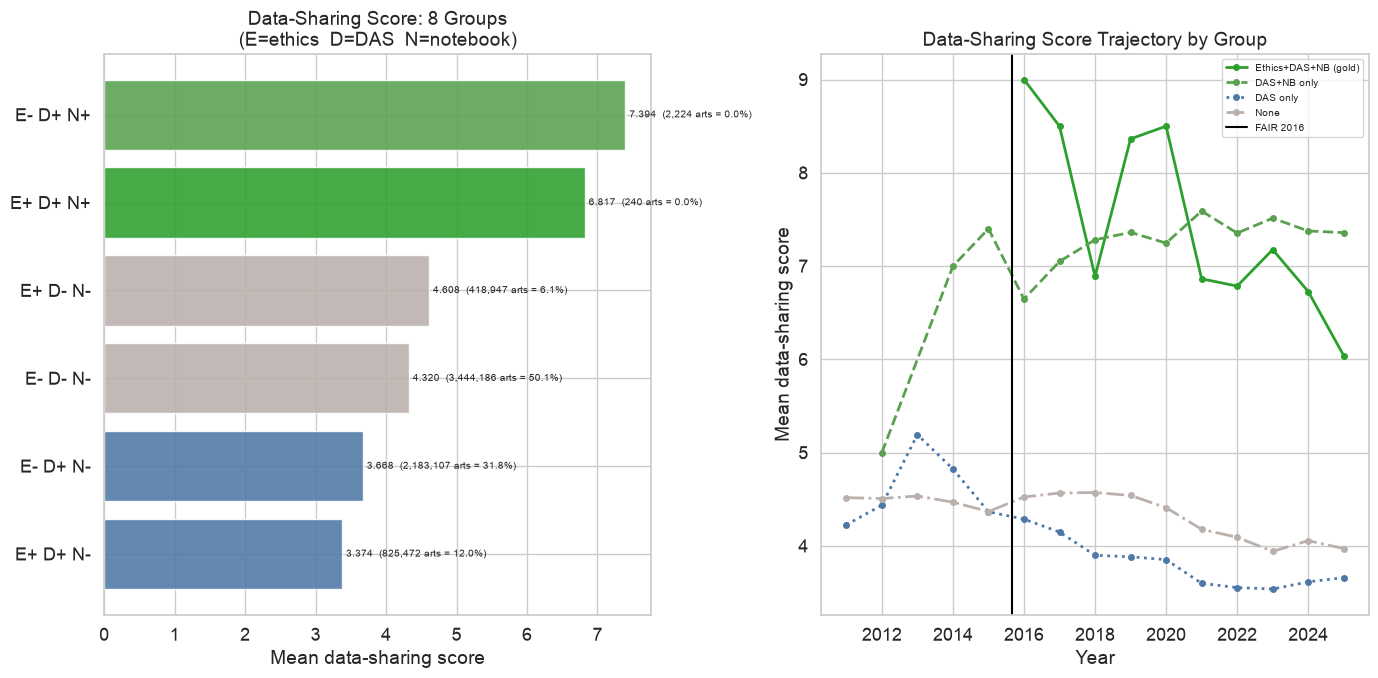

    grp3       n  mean_score  pct_corpus
E- D+ N+    2224    7.394335    0.032353
E+ D+ N+     240    6.816667    0.003491
E+ D- N-  418947    4.608086    6.094505
E- D- N- 3444186    4.319765   50.103256
E- D+ N- 2183107    3.668073   31.758090
E+ D+ N-  825472    3.373649   12.008305


In [19]:
if not HAS_ETHICS:
    print('Skipped — populate ethics_statement table first.')
else:
    df['grp3'] = (
        'E' + df['has_ethics'].map({True:'+', False:'-'}) + ' ' +
        'D' + df['has_das'].map({True:'+',   False:'-'}) + ' ' +
        'N' + df['has_notebook'].map({True:'+', False:'-'}))
    g3 = (df.groupby('grp3').agg(
        n=('article_id','count'), mean_score=('data_sharing_score','mean'),
        pct_corpus=('article_id', lambda x: len(x)/len(df)*100)
    ).reset_index().sort_values('mean_score', ascending=False))

    def g3clr(g):
        if 'E+ D+ N+' in g: return C_COMP
        if 'D+ N+' in g: return C_CODE
        if 'N+' in g: return C_NB
        if 'D+' in g: return C_PRE
        return C_NONE

    fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H + 2))

    ax = axes[0]
    clrs3 = [g3clr(g) for g in g3['grp3']]
    bars = ax.barh(g3['grp3'][::-1], g3['mean_score'][::-1],
                   color=clrs3[::-1], alpha=0.88, edgecolor='white')
    ax.bar_label(bars,
                 labels=[f'{m:.3f}  ({int(n):,} arts = {p:.1f}%)'
                         for m, n, p in zip(g3['mean_score'][::-1],
                                            g3['n'][::-1], g3['pct_corpus'][::-1])],
                 padding=3, fontsize=7.5)
    ax.set_xlabel('Mean data-sharing score')
    ax.set_title('Data-Sharing Score: 8 Groups\n(E=ethics  D=DAS  N=notebook)')

    ax = axes[1]
    for grp, lbl, clr, ls in [
            ('E+ D+ N+', 'Ethics+DAS+NB (gold)', C_COMP, '-'),
            ('E- D+ N+', 'DAS+NB only',          C_CODE, '--'),
            ('E- D+ N-', 'DAS only',              C_PRE,  ':'),
            ('E- D- N-', 'None',                  C_NONE, '-.')]:
        sub_yr = df[df['grp3'] == grp].groupby('year')['data_sharing_score'].mean()
        if len(sub_yr) >= 2:
            ax.plot(sub_yr.index, sub_yr.values, lw=2, marker='o', ms=4,
                    color=clr, ls=ls, label=lbl)
    ax.axvline(FAIR_YEAR - 0.33, color='black', lw=1.5, ls='-', label='FAIR 2016')
    ax.set_ylabel('Mean data-sharing score')
    ax.set_title('Data-Sharing Score Trajectory by Group')
    ax.set_xlabel('Year'); ax.legend(fontsize=7.5)

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_nb_14_threeway.png", **SAVEFIG_KWARGS)
    plt.show()
    print(g3.to_string(index=False))


---
## §15 — Journal-Level: Scatter, League Table, and Adoption S-Curve  *(extended)*

Three panels: (a) bubble chart of notebook rate vs data-sharing score by journal,
(b) first-adoption distribution with cumulative overlay,
(c) **new** logistic growth curve fitted to the cumulative adoption series
— estimating the saturation point and growth rate.

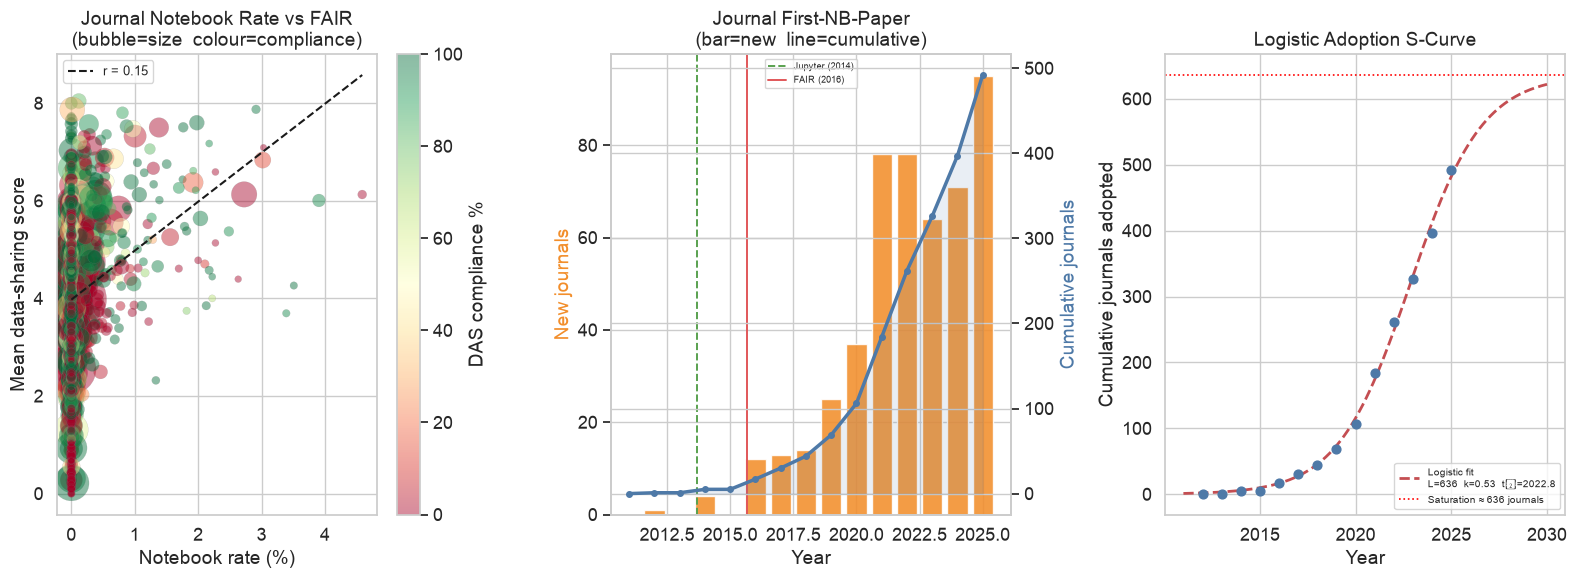

Journals with ≥1 notebook paper : 492
Median first adoption year       : 2022.0


In [20]:
j_agg = (df.groupby('journal_id').agg(
    n_total=('article_id','count'), n_nb=('has_notebook','sum'),
    n_das=('has_das','sum'), das_comp=('das_compliant','sum'),
    mean_score=('data_sharing_score','mean')).reset_index())
j_agg['nb_rate']   = j_agg['n_nb']  / j_agg['n_total'] * 100
j_agg['comp_rate'] = j_agg['das_comp'] / j_agg['n_das'].clip(1) * 100
j30 = j_agg[j_agg['n_total'] >= 30].merge(
    qdb('SELECT journal_id, title AS jtitle FROM journal'), on='journal_id', how='left')

j_first = (df[df['has_notebook']].groupby('journal_id')['year'].min()
           .reset_index().rename(columns={'year':'first_nb_year'}))
j_first = j_first.merge(j_agg[['journal_id','mean_score']], on='journal_id', how='left')
adopt_yr  = j_first['first_nb_year'].value_counts().sort_index()
med_adopt = j_first['first_nb_year'].median()
cum       = [(y,(j_first['first_nb_year']<=y).sum()) for y in range(2011,2026)]
cum_df    = pd.DataFrame(cum, columns=['year','n_adopted'])

fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H + 1))

ax = axes[0]
sc = ax.scatter(j30['nb_rate'], j30['mean_score'],
                alpha=0.45, s=np.sqrt(j30['n_total'])*4,
                c=j30['comp_rate'], cmap='RdYlGn', edgecolors='grey', linewidths=0.2)
plt.colorbar(sc, ax=ax, label='DAS compliance %')
if len(j30) >= 5:
    sl, ic, r, _, _ = stats.linregress(j30['nb_rate'].fillna(0), j30['mean_score'].fillna(0))
    xs = np.linspace(0, j30['nb_rate'].max(), 50)
    ax.plot(xs, ic+sl*xs, 'k--', lw=1.5, label=f'r = {r:.2f}')
    ax.legend(fontsize=9)
ax.set_xlabel('Notebook rate (%)'); ax.set_ylabel('Mean data-sharing score')
ax.set_title('Journal Notebook Rate vs FAIR\n(bubble=size  colour=compliance)')

ax = axes[1]
ax.bar(adopt_yr.index, adopt_yr.values, color=C_NB, alpha=0.88, edgecolor='white')
ax2r = ax.twinx()
ax2r.plot(cum_df['year'], cum_df['n_adopted'], lw=2.5, color=C_PRE, marker='o', ms=4)
ax2r.fill_between(cum_df['year'], cum_df['n_adopted'], alpha=0.12, color=C_PRE)
for x, c, ls, lbl in MILESTONES[:2]:
    ax.axvline(x, color=c, lw=1.4, ls=ls, label=lbl)
ax.set_xlabel('Year'); ax.set_ylabel('New journals', color=C_NB)
ax2r.set_ylabel('Cumulative journals', color=C_PRE)
ax.set_title('Journal First-NB-Paper\n(bar=new  line=cumulative)')
ax.legend(fontsize=6.5)

ax = axes[2]
# Fit logistic curve to cumulative adoption (as % of journals that ever adopted)
from scipy.optimize import curve_fit
def logistic(t, L, k, t0):
    return L / (1 + np.exp(-k * (t - t0)))
cum_df2 = cum_df[cum_df['n_adopted'] > 0].copy()
try:
    p0 = [cum_df2['n_adopted'].max()*1.3, 0.5, 2018]
    popt, _ = curve_fit(logistic, cum_df2['year'], cum_df2['n_adopted'],
                        p0=p0, maxfev=5000)
    L, k, t0 = popt
    xs_fit = np.linspace(2011, 2030, 200)
    ax.plot(xs_fit, logistic(xs_fit, *popt), 'r--', lw=2,
            label=f'Logistic fit\nL={L:.0f}  k={k:.2f}  t₀={t0:.1f}')
    ax.axhline(L, color='red', ls=':', lw=1.2, label=f'Saturation ≈ {L:.0f} journals')
except Exception:
    pass
ax.scatter(cum_df2['year'], cum_df2['n_adopted'], color=C_PRE, s=40, zorder=5)
ax.set_xlabel('Year'); ax.set_ylabel('Cumulative journals adopted')
ax.set_title('Logistic Adoption S-Curve')
ax.legend(fontsize=7.5)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_nb_15_journal.png", **SAVEFIG_KWARGS)
plt.show()
print(f'Journals with ≥1 notebook paper : {len(j_first):,}')
print(f'Median first adoption year       : {med_adopt}')


---
## §16 — Publisher League Table

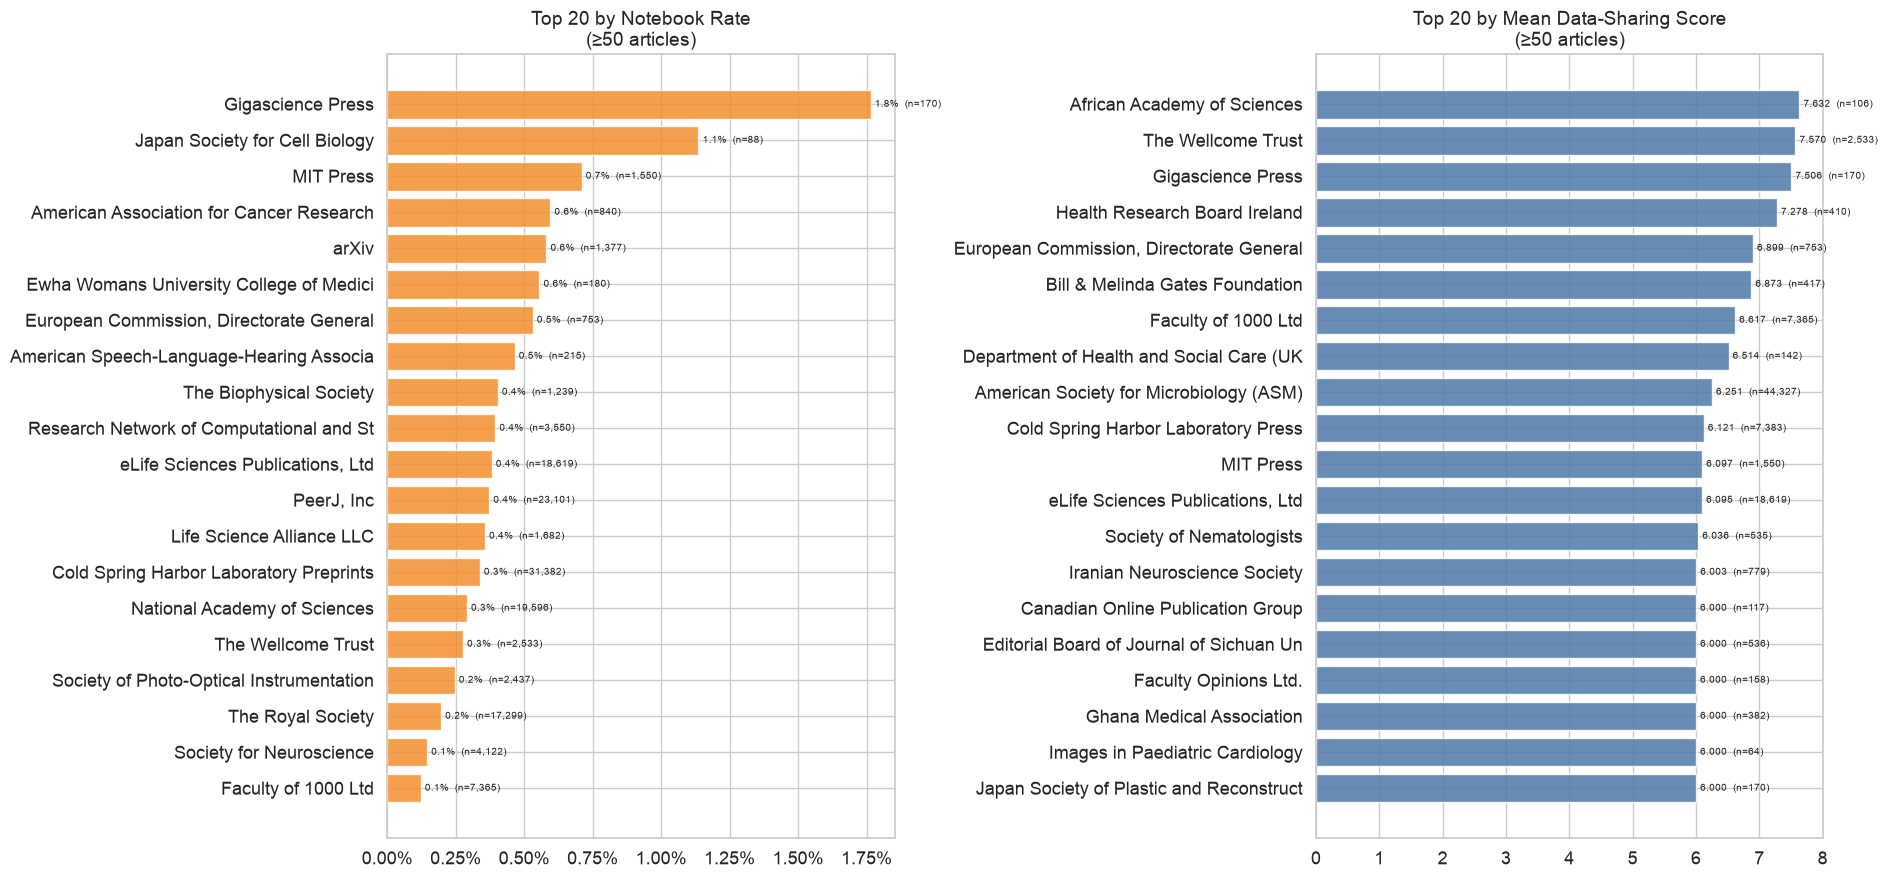

In [21]:
pub = (df.groupby('publisher').agg(
    n_total=('article_id','count'), n_nb=('has_notebook','sum'),
    mean_score=('data_sharing_score','mean')).reset_index())
pub['nb_rate'] = pub['n_nb'] / pub['n_total'] * 100
pub50 = pub[pub['n_total'] >= 50].copy()
pub50['label'] = pub50['publisher'].apply(lambda p: str(p or '(unknown)')[:40])

fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 5, FIG_H + 4))
for ax, sort_col, clr, fmt_str, title in [
        (axes[0], 'nb_rate',   C_NB,  '{:.1f}%', 'Top 20 by Notebook Rate'),
        (axes[1], 'mean_score', C_PRE, '{:.3f}',  'Top 20 by Mean Data-Sharing Score')]:
    sub = pub50.nlargest(20, sort_col)
    bars = ax.barh(sub['label'][::-1], sub[sort_col][::-1],
                   color=clr, alpha=0.85, edgecolor='white')
    ax.bar_label(bars,
                 labels=[fmt_str.format(v) + f'  (n={int(n):,})'
                         for v, n in zip(sub[sort_col][::-1], sub['n_total'][::-1])],
                 padding=3, fontsize=7.5)
    if sort_col == 'nb_rate':
        ax.xaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_title(title + '\n(≥50 articles)')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_nb_16_publisher.png", **SAVEFIG_KWARGS)
plt.show()


---
## §17 — OA Tier × Notebook Sharing  *(Stage 6)*

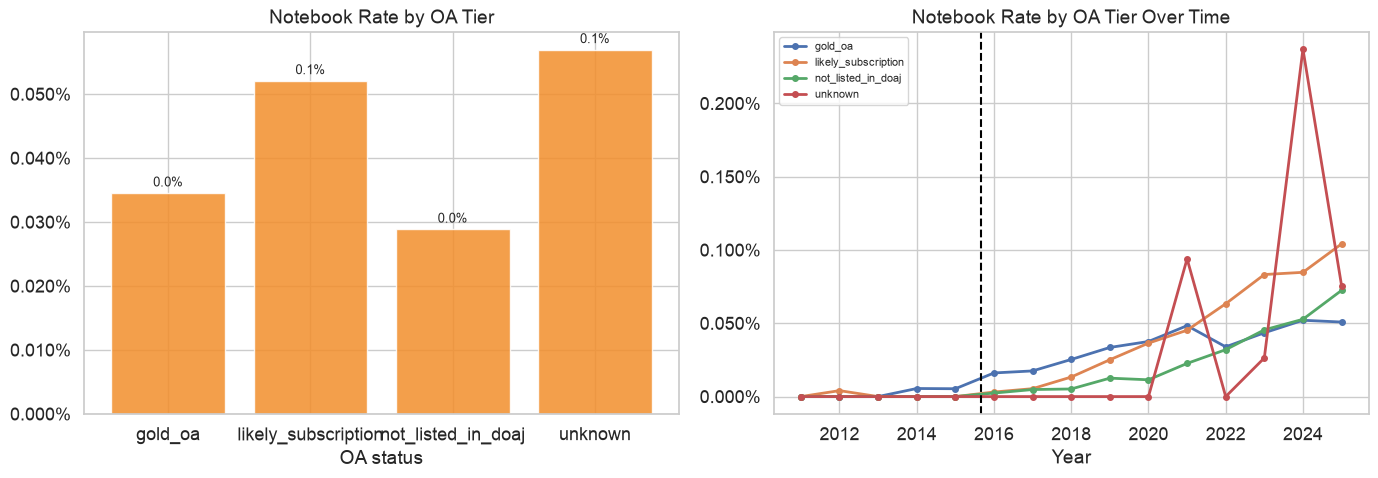

          oa_status  n_total  n_nb  mean_score  nb_rate
            gold_oa  2510181   866        4.07     0.03
likely_subscription  1425422   742        3.92     0.05
 not_listed_in_doaj  2908702   839        4.02     0.03
            unknown    29871    17        3.85     0.06


In [22]:
if not HAS_OA:
    print('Skipped — OA status data not available in this database.')
else:
    oa_nb = (df.groupby('oa_status').agg(
        n_total=('article_id','count'), n_nb=('has_notebook','sum'),
        mean_score=('data_sharing_score','mean')).reset_index())
    oa_nb['nb_rate'] = oa_nb['n_nb'] / oa_nb['n_total'] * 100
    yr_oa = (df.groupby(['year','oa_status'])['has_notebook'].mean().unstack() * 100)

    fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))
    ax = axes[0]
    bars = ax.bar(oa_nb['oa_status'], oa_nb['nb_rate'], color=C_NB, alpha=0.85, edgecolor='white')
    ax.bar_label(bars, fmt='{:.1f}%', padding=3, fontsize=9)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_title('Notebook Rate by OA Tier'); ax.set_xlabel('OA status')

    ax = axes[1]
    for col in yr_oa.columns:
        ax.plot(yr_oa.index, yr_oa[col], lw=2, marker='o', ms=4, label=col)
    ax.axvline(FAIR_YEAR - 0.33, color='black', lw=1.5, ls='--')
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_title('Notebook Rate by OA Tier Over Time'); ax.set_xlabel('Year')
    ax.legend(fontsize=8)

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_nb_17_oa.png", **SAVEFIG_KWARGS)
    plt.show()
    print(oa_nb.round(2).to_string(index=False))


---
## §18 — Discipline Breakdown  *(Stage 6)*

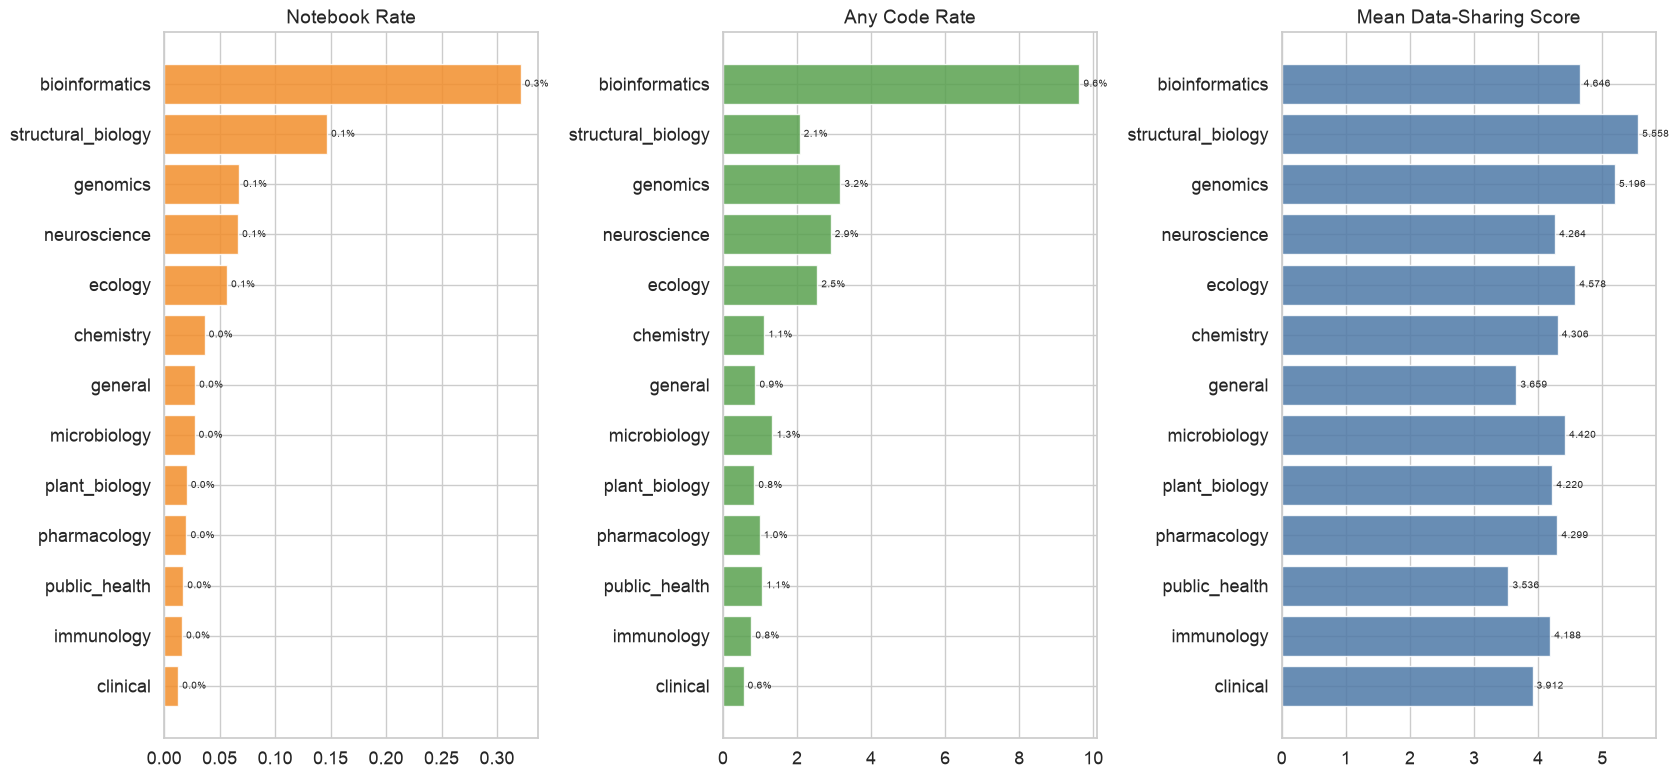


FAIR uplift from notebooks within discipline:
        discipline  uplift
     public_health   3.559
           general   3.503
        immunology   3.431
         chemistry   3.219
     plant_biology   3.197
      pharmacology   3.014
      neuroscience   2.923
    bioinformatics   2.838
          clinical   2.811
           ecology   2.805
      microbiology   2.803
          genomics   2.652
structural_biology   2.145


In [23]:
if not HAS_DISC:
    print('Skipped — discipline data not available in this database.')
else:
    df_disc = qdb("""SELECT a.article_id, ad.discipline, a.year AS year
                  FROM article a JOIN article_discipline ad ON ad.article_id = a.article_id
                  WHERE a.year BETWEEN 2011 AND 2025""")
    df_disc = df_disc.merge(df[['article_id','has_notebook','has_any_code','data_sharing_score','era']],
                            on='article_id')
    dagg = (df_disc.groupby('discipline').agg(
        n_total=('article_id','count'), n_nb=('has_notebook','sum'),
        n_code=('has_any_code','sum'), mean_score=('data_sharing_score','mean')).reset_index())
    dagg['nb_rate']   = dagg['n_nb']   / dagg['n_total'] * 100
    dagg['code_rate'] = dagg['n_code'] / dagg['n_total'] * 100
    dagg = dagg.sort_values('nb_rate', ascending=False)

    uplift_rows = []
    for disc in dagg['discipline']:
        sub = df_disc[df_disc['discipline'] == disc]
        nb_s = sub[sub['has_notebook'] ]['data_sharing_score'].dropna()
        no_s = sub[~sub['has_notebook']]['data_sharing_score'].dropna()
        if len(nb_s) >= 5 and len(no_s) >= 5:
            uplift_rows.append({'discipline': disc, 'uplift': nb_s.mean() - no_s.mean()})
    df_uplift = pd.DataFrame(uplift_rows).sort_values('uplift', ascending=False)

    fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 3, FIG_H + 3))
    for ax, col, clr, title in [
            (axes[0], 'nb_rate',   C_NB,  'Notebook Rate'),
            (axes[1], 'code_rate', C_CODE,'Any Code Rate'),
            (axes[2], 'mean_score', C_PRE, 'Mean Data-Sharing Score')]:
        bars = ax.barh(dagg['discipline'][::-1], dagg[col][::-1],
                       color=clr, alpha=0.85, edgecolor='white')
        ax.bar_label(bars, fmt='{:.1f}%' if 'rate' in col else '{:.3f}',
                     padding=3, fontsize=7.5)
        ax.set_title(title)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_nb_18_discipline.png", **SAVEFIG_KWARGS)
    plt.show()
    if len(df_uplift) > 0:
        print('\nFAIR uplift from notebooks within discipline:')
        print(df_uplift.round(3).to_string(index=False))


---
## §19 — Funder Breakdown  *(Stage 6)*

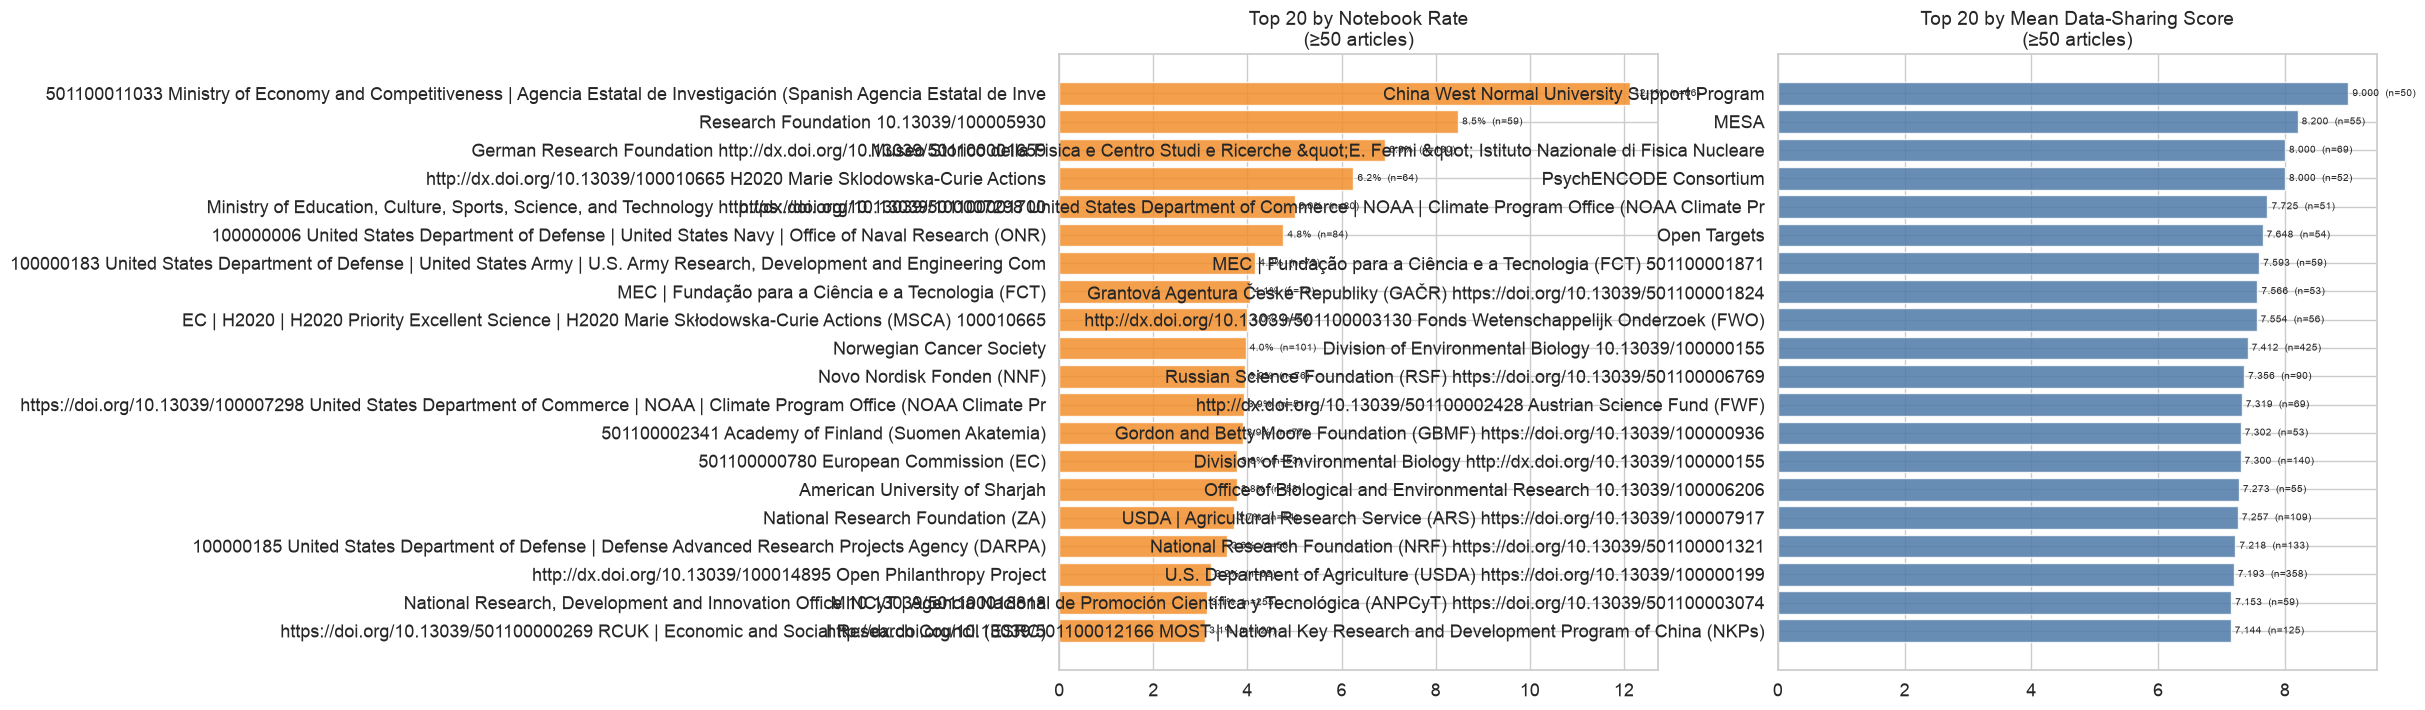

In [24]:
if not HAS_FUNDER:
    print('Skipped — funder data not available in this database.')
else:
    df_fund = qdb("""SELECT af.article_id, af.funder_norm AS funder
                  FROM article_funder af JOIN article a ON a.article_id = af.article_id
                  WHERE af.funder_norm != 'none' AND a.year BETWEEN 2011 AND 2025""")
    df_fund = df_fund.merge(df[['article_id','has_notebook','data_sharing_score','era']], on='article_id')
    fagg = (df_fund.groupby('funder').agg(
        n=('article_id','count'),
        nb_rate=('has_notebook', lambda x: x.mean()*100),
        mean_score=('data_sharing_score','mean')).reset_index())
    fagg50 = fagg[fagg['n'] >= 50].copy()

    fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 3, FIG_H + 3))
    for ax, sort_col, clr, fmt_str, title in [
            (axes[0], 'nb_rate',   C_NB,  '{:.1f}%', 'Top 20 by Notebook Rate'),
            (axes[1], 'mean_score', C_PRE, '{:.3f}',  'Top 20 by Mean Data-Sharing Score')]:
        sub = fagg50.nlargest(20, sort_col)
        bars = ax.barh(sub['funder'][::-1], sub[sort_col][::-1],
                       color=clr, alpha=0.85, edgecolor='white')
        ax.bar_label(bars,
                     labels=[fmt_str.format(v) + f'  (n={int(n):,})'
                             for v, n in zip(sub[sort_col][::-1], sub['n'][::-1])],
                     padding=3, fontsize=7.5)
        ax.set_title(title + '\n(≥50 articles)')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_nb_19_funder.png", **SAVEFIG_KWARGS)
    plt.show()


---
## §20 — Statistical Summary + Exports

In [ ]:
print('=' * 72)
print('JUPYTER NOTEBOOKS IN DAS  —  COMPREHENSIVE SUMMARY')
print('=' * 72)

sc_nb = df[ df['has_notebook']                        ]['data_sharing_score'].dropna()
sc_cr = df[ df['has_code_repo'] & ~df['has_notebook'] ]['data_sharing_score'].dropna()
sc_nc = df[~df['has_any_code']                        ]['data_sharing_score'].dropna()

nb_pre  = df[df['year'] < JUPYTER_YEAR  ]['has_notebook'].mean() * 100
nb_jup  = df[(df['year']>=JUPYTER_YEAR) & (df['year']<FAIR_YEAR)]['has_notebook'].mean()*100
nb_fair = df[(df['year']>=FAIR_YEAR)    & (df['year']<MANDATE_YEAR)]['has_notebook'].mean()*100
nb_man  = df[df['year'] >= MANDATE_YEAR ]['has_notebook'].mean() * 100

for lbl, val in [
        ('Total articles 2011-2025',           f'{len(df):,}'),
        ('Has notebook signal',                 f'{df["has_notebook"].sum():,}  ({df["has_notebook"].mean()*100:.2f}%)'),
        ('Has any code signal',                 f'{df["has_any_code"].sum():,}  ({df["has_any_code"].mean()*100:.2f}%)'),
        ('',                                    ''),
        ('NB rate pre-Jupyter   (2012-13)',      f'{nb_pre:.2f}%'),
        ('NB rate Jupyter adopt (2014-15)',      f'{nb_jup:.2f}%'),
        ('NB rate FAIR era      (2016-18)',      f'{nb_fair:.2f}%'),
        ('NB rate Mandate era   (2019-24)',      f'{nb_man:.2f}%'),
        ('',                                    ''),
        ('Mean Score: notebook',                  f'{sc_nb.mean():.4f}'),
        ('Mean Score: code-repo only',            f'{sc_cr.mean():.4f}'),
        ('Mean Score: no code',                   f'{sc_nc.mean():.4f}'),
        ('Uplift notebook − no-code',            f'{sc_nb.mean()-sc_nc.mean():+.4f}'),
        ('',                                    ''),
        ('Authors: mean with NB',               f'{df[df["has_notebook"]]["n_authors"].mean():.2f}'),
        ('Authors: mean without NB',            f'{df[~df["has_notebook"]]["n_authors"].mean():.2f}'),
]:
    print(f'  {lbl:44} {val}')

print('\nMann-Whitney U tests (two-sided):')
for lbl, a, b in [('Notebook  vs No-code  ', sc_nb, sc_nc),
                   ('Code-repo vs No-code  ', sc_cr, sc_nc),
                   ('Notebook  vs Code-repo', sc_nb, sc_cr)]:
    if len(a) >= 2 and len(b) >= 2:
        u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
        # u/(n1*n2) is CLES, not rank-biserial r (CLES=0.5 is the null point).
        # True rank-biserial r = 2*CLES - 1; see 06_gender_analysis.ipynb.
        cles = u / (len(a) * len(b))
        r    = 2 * cles - 1
        sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
        print(f'  {lbl}  Δ={a.mean()-b.mean():+.4f}  p={p:.2e}  r={r:.3f}  {sig}')


In [26]:
export_dir = Path('../results/fair_notebooks_das_exports')
export_dir.mkdir(parents=True, exist_ok=True)

exports = {
    'nb_flags_per_article.csv': df[['article_id','year','era','has_notebook',
        'has_code_repo','has_any_code','script_text','has_das','das_tier',
        'data_sharing_score','das_cat','nb_grp','code_type','n_authors']],
    'nb_prevalence_by_year.csv': yr,
    'nb_by_era.csv': (df.groupby('era').agg(
        n=('article_id','count'),
        nb_rate=('has_notebook', lambda x: x.mean()*100),
        mean_score=('data_sharing_score','mean')).reindex(ERA_ORDER).reset_index()),
    'platform_stats.csv':    df_plat,
    'keyword_stats.csv':     df_kw,
    'repo_tier_stats.csv':   df_repo,
    'journal_nb_stats.csv':  j_agg,
    'journal_adoption.csv':  j_first,
    'author_count_nb.csv':   df.groupby('auth_bin', observed=True).agg(
        n=('article_id','count'),
        nb_rate=('has_notebook', lambda x: x.mean()*100),
        mean_score=('data_sharing_score','mean')).reset_index(),
    'coevolution_by_year.csv': yr_coev,
}
for fname, df_e in exports.items():
    if df_e is None or len(df_e) == 0:
        print(f'  skipped (empty): {fname}'); continue
    df_e.to_csv(export_dir / fname, index=False)
    print(f'  saved  {fname}  ({len(df_e):,} rows)')

con.close()
print('\nAll done.')


  saved  nb_flags_per_article.csv  (6,874,176 rows)
  saved  nb_prevalence_by_year.csv  (15 rows)
  saved  nb_by_era.csv  (4 rows)
  saved  platform_stats.csv  (8 rows)
  saved  keyword_stats.csv  (15 rows)
  saved  repo_tier_stats.csv  (9 rows)
  saved  journal_nb_stats.csv  (21,955 rows)
  saved  journal_adoption.csv  (492 rows)
  saved  author_count_nb.csv  (6 rows)
  saved  coevolution_by_year.csv  (15 rows)

All done.
